In [ ]:
# for larger dataframes
import dask.dataframe as dd

# for small dataframes
import pandas as pd

import folium #open street map

import datetime
import time

In [2]:
import numpy as np

In [3]:
START_YEAR_MONTH = "2022-01"
END_YEAR_MONTH = "2022-03"

# Build list of monthly bronze parquet paths from the date range
s_year, s_month = (int(x) for x in START_YEAR_MONTH.split("-"))
e_year, e_month = (int(x) for x in END_YEAR_MONTH.split("-"))
bronze_paths = []
year, mo = s_year, s_month
while (year, mo) <= (e_year, e_month):
    tag = f"{year}_{mo:02d}"
    bronze_paths.append(f"../data/bronze/{tag}/{tag}.parquet")
    mo += 1
    if mo > 12:
        mo = 1
        year += 1

month = dd.read_parquet(bronze_paths)
month = month[
    (month["tpep_pickup_datetime"] >= f"{START_YEAR_MONTH}-01") &
    (month["tpep_pickup_datetime"] < pd.Timestamp(year=e_year, month=e_month, day=1) + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1))
]
print(month.columns)

Index(['vendorid', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'ratecodeid', 'store_and_fwd_flag',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'airport_fee'],
      dtype='str')


## Problem statement
<h3> Find out the pick up density give the time and a region.</h3>
<p> 
We will be taking the data of year 2022(12 months data) as train data, and test our model on year 2023 data.

The prediction time will be aimed to make accurate prediction for several hours ahead
</p>

In [4]:
# helper function to convert locationid to longitude and latitude

import geopandas as gpd

def build_zone_lookup(shp_path: str) -> pd.DataFrame:
    """Build a LocationID → (longitude, latitude) lookup from the taxi zones shapefile.

    Each zone is represented by the centroid of its polygon, reprojected to WGS84.

    Args:
        shp_path: Path to the taxi_zones.shp file.

    Returns:
        DataFrame with columns [LocationID, longitude, latitude].
    """
    gdf = gpd.read_file(shp_path).to_crs("EPSG:4326")
    centroids = gdf.to_crs("EPSG:3857").geometry.centroid.to_crs("EPSG:4326")
    lookup = pd.DataFrame({
        "LocationID": gdf["LocationID"].astype(int),
        "longitude": centroids.x,
        "latitude": centroids.y,
    })
    # Drop duplicates so the index is unique for .map()
    return lookup.drop_duplicates(subset="LocationID")


def add_pickup_coords(df: dd.DataFrame, shp_path: str) -> dd.DataFrame:
    """Map pulocationid to pickup_longitude and pickup_latitude.

    Args:
        df: Dask DataFrame containing a ``pulocationid`` column.
        shp_path: Path to the taxi_zones.shp file.

    Returns:
        Dask DataFrame with two new columns: pickup_longitude, pickup_latitude.
    """
    lookup = build_zone_lookup(shp_path)
    lon_map = lookup.set_index("LocationID")["longitude"]
    lat_map = lookup.set_index("LocationID")["latitude"]

    df["pickup_longitude"] = df["pulocationid"].map(lon_map)
    df["pickup_latitude"]  = df["pulocationid"].map(lat_map)
    return df


SHP_PATH = "../data/reference/taxi_zones.shp"
month = add_pickup_coords(month, SHP_PATH)
month[["pulocationid", "pickup_longitude", "pickup_latitude"]].head()

/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that you are using.
  Before: .map(func)
  After:  .map(func, meta=('pulocationid', 'float64'))

  warnings.warn(meta_warning(meta, method="map"))
/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that yo

,pulocationid,pickup_longitude,pickup_latitude
0,138,-73.873629,40.774376
1,132,-73.786535,40.646987
2,170,-73.978492,40.747746
3,79,-73.985937,40.727620
4,68,-73.999917,40.748428


### Data Cleaning
### 1. Pickup Latitude and Pickup Longitude

From source https://www.flickr.com/places/info/2459115'
New York is bounded by the location cordinates(lat,long) - (40.5774, -74.15) & (40.9176,-73.7004)

Therefore, any cordinates not within these cordinates are not considered by us as we are only concerned with pickups which originate within New York.

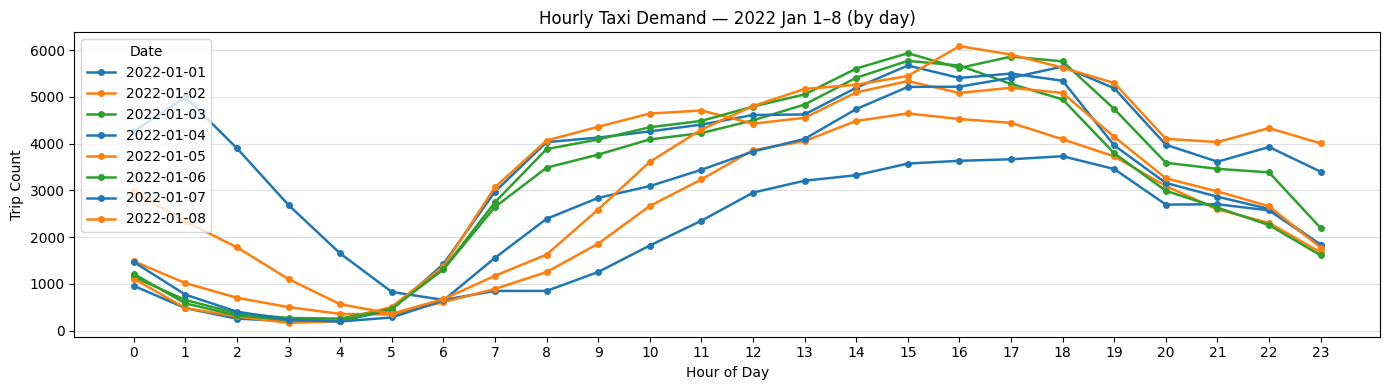

In [5]:
import matplotlib.pyplot as plt

# First 3 days — compute to pandas before plotting
first_3_days = month[month["tpep_pickup_datetime"] < "2022-01-09"]

hourly_demand = (
    first_3_days
    .groupby(first_3_days["tpep_pickup_datetime"].dt.floor("h"))
    .size()
    .rename("trip_count")
    .reset_index()
    .rename(columns={"tpep_pickup_datetime": "hour"})
    .compute()
)

hourly_demand["date"] = hourly_demand["hour"].dt.date
hourly_demand["hour_of_day"] = hourly_demand["hour"].dt.hour

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
fig, ax = plt.subplots(figsize=(14, 4))

for i, (day, group) in enumerate(hourly_demand.groupby("date")):
    ax.plot(
        group["hour_of_day"], group["trip_count"],
        marker="o", markersize=4, linewidth=1.8,
        color=colors[i % len(colors)],
        label=str(day),
    )

ax.set_xticks(range(0, 24))
ax.set_title("Hourly Taxi Demand — 2022 Jan 1–8 (by day)")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Trip Count")
ax.legend(title="Date")
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

### 1. Pickup Latitude and Pickup Longitude

From source https://www.flickr.com/places/info/2459115'
New York is bounded by the location cordinates(lat,long) - (40.5774, -74.15) & (40.9176,-73.7004)

Therefore, any cordinates not within these cordinates are not considered by us as we are only concerned with pickups which originate within New York.

In [6]:
# Plotting pickup coordinates which are outside the bounding box of New York
outlier_locations = month[
    (month.pickup_longitude <= -74.15) |
    (month.pickup_latitude  <= 40.5774) |
    (month.pickup_longitude >= -73.7004) |
    (month.pickup_latitude  >= 40.9176)
]

# Random sample of 10k rows — computed only for the sample, not the full outlier set
sample_locations = outlier_locations.sample(frac=1).head(10000, npartitions=-1)

map_osm = folium.Map(location=[40.734695, -73.990372], tiles="CartoDB positron")

for _, row in sample_locations.iterrows():
    if int(row["pickup_latitude"]) != 0:
        folium.Marker(location=[row["pickup_latitude"], row["pickup_longitude"]]).add_to(map_osm)

map_osm

### 2. Trip Durations:
According to NYC Taxi & Limousine Commision Regulations the maximum allowed trip duration in a 24 hour interval is 12 hours.

Also, we duration can never be less than 0

Removing invalid trip duration make sure the data that we get is an actual trip data rather than a input error

Original: 9071207
Removing outliers from NY boundaries: 8956708 114499

trip times percentiles...
0.0th percentile -71.75
10.0th percentile 0.0
20.0th percentile 0.0
30.0th percentile 0.0
40.0th percentile 0.017
50.0th percentile 0.017
60.0th percentile 0.017
70.0th percentile 0.017
80.0th percentile 0.017
90.0th percentile 0.033
100.0th percentile 4.283
(8956708, 13) before first
Removing outliers from trip times: 8956708 0


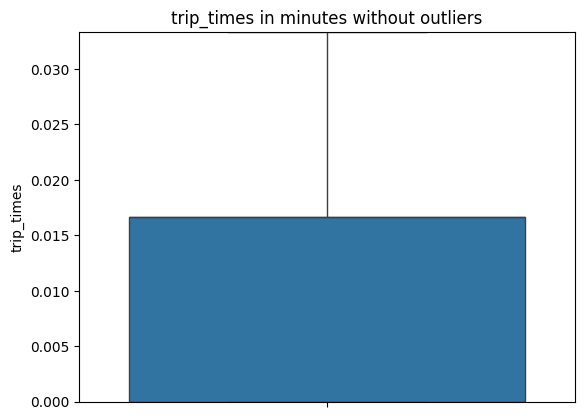


trip distance percentiles...
0.0th percentile 0.0
10.0th percentile 0.699999988079071
20.0th percentile 0.949999988079071
30.0th percentile 1.2000000476837158
40.0th percentile 1.4800000190734863
50.0th percentile 1.7999999523162842
60.0th percentile 2.200000047683716
70.0th percentile 2.799999952316284
80.0th percentile 3.8399999141693115
90.0th percentile 7.320000171661377
100.0th percentile 263173.0
Removing outliers from trip distance: 8841246 115462


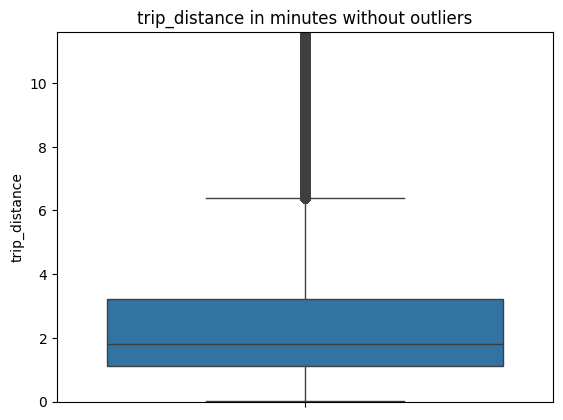


Speed percentiles...
0.0th percentile 0.0
10.0th percentile 0.0
20.0th percentile 0.0
30.0th percentile 0.0
40.0th percentile 3456.0
50.0th percentile 5148.0
60.0th percentile 6804.0
70.0th percentile 8640.0
80.0th percentile 11556.0
90.0th percentile 17819.999
100.0th percentile 82584.002
Removing outliers from trip speed: 2971360 5869886


/tmp/ipykernel_1256/1039942115.py:40: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.ylim(0, var[int(float(95) * len(var) / 100)])


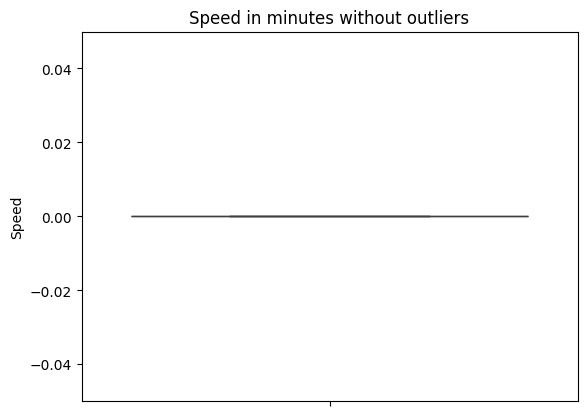

Total outliers removed 6099847


,vendorid,payment_type,passenger_count,trip_distance,pickup_longitude,pickup_latitude,pulocationid,dolocationid,ratecodeid,store_and_fwd_flag,trip_times,pickup_times,Speed
6,2,2,2,1.46,-73.973049,40.791705,238,263,1,N,0.0,1640995,0.0
8,2,2,1,5.05,-73.786535,40.646987,132,216,1,N,0.0,1640995,0.0
9,1,2,1,0.20,-73.919694,40.761493,7,7,1,N,0.0,1640995,0.0
10,2,1,1,2.17,-73.951010,40.778766,263,233,1,N,0.0,1640995,0.0
12,2,2,6,2.24,-73.985937,40.727620,79,233,1,N,0.0,1640995,0.0


In [7]:
import numpy as np
import seaborn as sns

def return_with_trip_times():
    """Build a pandas DataFrame with trip duration, pickup unix time, and speed."""
    duration = month[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].compute()

    # Vectorised unix timestamp conversion (seconds since epoch)
    pickup_unix = duration["tpep_pickup_datetime"].astype("int64") // 10**9
    dropoff_unix = duration["tpep_dropoff_datetime"].astype("int64") // 10**9

    # Trip duration in minutes
    trip_times = (dropoff_unix - pickup_unix) / 60.0

    cols = [
        "vendorid", "payment_type", "passenger_count", "trip_distance",
        "pickup_longitude", "pickup_latitude",
        "pulocationid", "dolocationid", "ratecodeid", "store_and_fwd_flag",
    ]
    new_frame = month[cols].compute()

    new_frame["trip_times"] = trip_times.values
    new_frame["pickup_times"] = pickup_unix.values
    new_frame["Speed"] = np.where(
        new_frame["trip_times"] > 0,
        60 * (new_frame["trip_distance"] / new_frame["trip_times"]),
        0.0,
    )
    return new_frame


frame_with_durations = return_with_trip_times()


def plot_boxplot(new_frame, string1, string2):
    var = new_frame[string1].values
    var = np.sort(var, axis=None)
    if string2 != "":
        plt.figure()
        plt.ylim(0, var[int(float(95) * len(var) / 100)])
        sns.boxplot(y=string1, data=new_frame)
        plt.title(string1 + " in minutes without outliers")
        plt.show()
    return var


def remove_outliers(new_frame):
    print("Original:", new_frame.shape[0])
    a = new_frame.shape[0]

    # Remove pickups outside NYC bounding box (already filtered, but kept for completeness)
    new_frame = new_frame[
        (new_frame.pickup_longitude >= -74.15) & (new_frame.pickup_longitude <= -73.7004) &
        (new_frame.pickup_latitude >= 40.5774) & (new_frame.pickup_latitude <= 40.9176)
    ]
    print("Removing outliers from NY boundaries:", new_frame.shape[0], (a - new_frame.shape[0]))
    b = new_frame.shape[0]

    print("\ntrip times percentiles...")
    var = plot_boxplot(new_frame, "trip_times", "")
    for i in range(0, len(var), int(float(10) * len(var) / 100)):
        print("{}th percentile {}".format(round(float(i) / len(var), 3) * 100, round(var[i], 3)))

    print(new_frame.shape, "before first")
    print("Removing outliers from trip times:", new_frame.shape[0], (b - new_frame.shape[0]))
    var = plot_boxplot(new_frame, "trip_times", "out")

    # ── Trip distance ─────────────────────────────────────────────────────────
    print("\ntrip distance percentiles...")
    var = plot_boxplot(new_frame, "trip_distance", "")
    for i in range(0, len(var), int(float(10) * len(var) / 100)):
        print("{}th percentile {}".format(round(float(i) / len(var), 3) * 100, round(var[i], 3)))

    c = new_frame.shape[0]
    new_frame = new_frame[(new_frame.trip_distance > 0) & (new_frame.trip_distance < 23)]
    print("Removing outliers from trip distance:", new_frame.shape[0], (c - new_frame.shape[0]))
    var = plot_boxplot(new_frame, "trip_distance", "out")

    # ── Speed ─────────────────────────────────────────────────────────────────
    print("\nSpeed percentiles...")
    var = plot_boxplot(new_frame, "Speed", "")
    for i in range(0, len(var), int(float(10) * len(var) / 100)):
        print("{}th percentile {}".format(round(float(i) / len(var), 3) * 100, round(var[i], 3)))

    d = new_frame.shape[0]
    new_frame = new_frame[(new_frame.Speed <= 65) & (new_frame.Speed >= 0)]
    print("Removing outliers from trip speed:", new_frame.shape[0], (d - new_frame.shape[0]))
    var = plot_boxplot(new_frame, "Speed", "out")

    print("Total outliers removed", a - new_frame.shape[0])
    return new_frame


frame_with_durations_outliers_removed = remove_outliers(frame_with_durations)
frame_with_durations_outliers_removed.head()

In [8]:
frame_with_durations_outliers_removed.head()

,vendorid,payment_type,passenger_count,trip_distance,pickup_longitude,pickup_latitude,pulocationid,dolocationid,ratecodeid,store_and_fwd_flag,trip_times,pickup_times,Speed
6,2,2,2,1.46,-73.973049,40.791705,238,263,1,N,0.0,1640995,0.0
8,2,2,1,5.05,-73.786535,40.646987,132,216,1,N,0.0,1640995,0.0
9,1,2,1,0.20,-73.919694,40.761493,7,7,1,N,0.0,1640995,0.0
10,2,1,1,2.17,-73.951010,40.778766,263,233,1,N,0.0,1640995,0.0
12,2,2,6,2.24,-73.985937,40.727620,79,233,1,N,0.0,1640995,0.0


In [5]:
import seaborn as sns
#trip times
def dist_of_params(frame, variable, title):
    sns.FacetGrid(frame, height=6) \
      .map(sns.kdeplot, variable) \
      .add_legend()
    plt.title(title)
    plt.show()

#trip times
dist_of_params(frame_with_durations_outliers_removed,'trip_times','time for cab trips distribution(in minutes)')

#log trip times
log_trip_times = frame_with_durations_outliers_removed.trip_times.values
frame_with_durations_outliers_removed['log_times'] = np.log(log_trip_times)
dist_of_params(frame_with_durations_outliers_removed,'log_times','log of time for cab trips distribution')

#trip distances
dist_of_params(frame_with_durations_outliers_removed,'trip_distance','distance for cab trips distribution')

#log trip distances
log_trip_distance = frame_with_durations_outliers_removed.trip_distance.values
frame_with_durations_outliers_removed['log_distance'] = np.log(log_trip_distance)
dist_of_params(frame_with_durations_outliers_removed,'log_distance','log of distance for cab trips distribution')

#speed
dist_of_params(frame_with_durations_outliers_removed,'Speed','speed for cab trips distribution')

#log speed
log_speed = frame_with_durations_outliers_removed.Speed.values
frame_with_durations_outliers_removed['log_speed'] = np.log(log_speed)
dist_of_params(frame_with_durations_outliers_removed,'log_speed','log of speed for cab trips distribution')

NameError: name 'frame_with_durations_outliers_removed' is not defined

## Pickup and dropoff locations on maps:

From the remaining data, I will visualize the density of pickup location on maps

In [9]:
# Build LocationID → zone name, borough lookup from the shapefile
zone_lookup = gpd.read_file(SHP_PATH)[["LocationID", "zone", "borough"]]
zone_lookup["LocationID"] = zone_lookup["LocationID"].astype(int)
zone_lookup = zone_lookup.drop_duplicates(subset="LocationID")

# Map zone name and borough onto pickup and dropoff location IDs
zone_map = zone_lookup.set_index("LocationID")["zone"]
borough_map = zone_lookup.set_index("LocationID")["borough"]

month["pickup_zone"] = month["pulocationid"].map(zone_map)
month["pickup_borough"] = month["pulocationid"].map(borough_map)
month["dropoff_zone"] = month["dolocationid"].map(zone_map)
month["dropoff_borough"] = month["dolocationid"].map(borough_map)

month[["pulocationid", "pickup_zone", "pickup_borough",
       "dolocationid", "dropoff_zone", "dropoff_borough"]].head(10)

/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that you are using.
  Before: .map(func)
  After:  .map(func, meta=('pulocationid', 'str'))

  warnings.warn(meta_warning(meta, method="map"))
/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that you ar

,pulocationid,pickup_zone,pickup_borough,dolocationid,dropoff_zone,dropoff_borough
0,138,LaGuardia Airport,Queens,255,Williamsburg (North Side),Brooklyn
1,132,JFK Airport,Queens,215,South Jamaica,Queens
2,170,Murray Hill,Manhattan,68,East Chelsea,Manhattan
3,79,East Village,Manhattan,209,Seaport,Manhattan
4,68,East Chelsea,Manhattan,256,Williamsburg (South Side),Brooklyn
5,132,JFK Airport,Queens,236,Upper East Side North,Manhattan
6,238,Upper West Side North,Manhattan,263,Yorkville West,Manhattan
7,170,Murray Hill,Manhattan,166,Morningside Heights,Manhattan
8,132,JFK Airport,Queens,216,South Ozone Park,Queens
9,7,Astoria,Queens,7,Astoria,Queens


In [10]:
# Borough color mapping using actual borough names from the shapefile
BOROUGH_COLORS = {
    "Manhattan": "#FFFFFF",
    "Queens":    "#00FFFF",
    "Brooklyn":  "#FFD700",
    "Bronx":     "#DC143C",
    "Staten Island": "#FF69B4",
    "EWR":       "#7CFC00",
}

def get_borough_colors(frame: pd.DataFrame, borough_col: str) -> list[str]:
    """Return a list of hex colors corresponding to the borough column.

    Args:
        frame: DataFrame with a borough column (e.g. pickup_borough).
        borough_col: Name of the borough column.

    Returns:
        List of hex color strings, one per row.
    """
    return frame[borough_col].map(
        lambda b: BOROUGH_COLORS.get(b, "#808080")
    ).tolist()

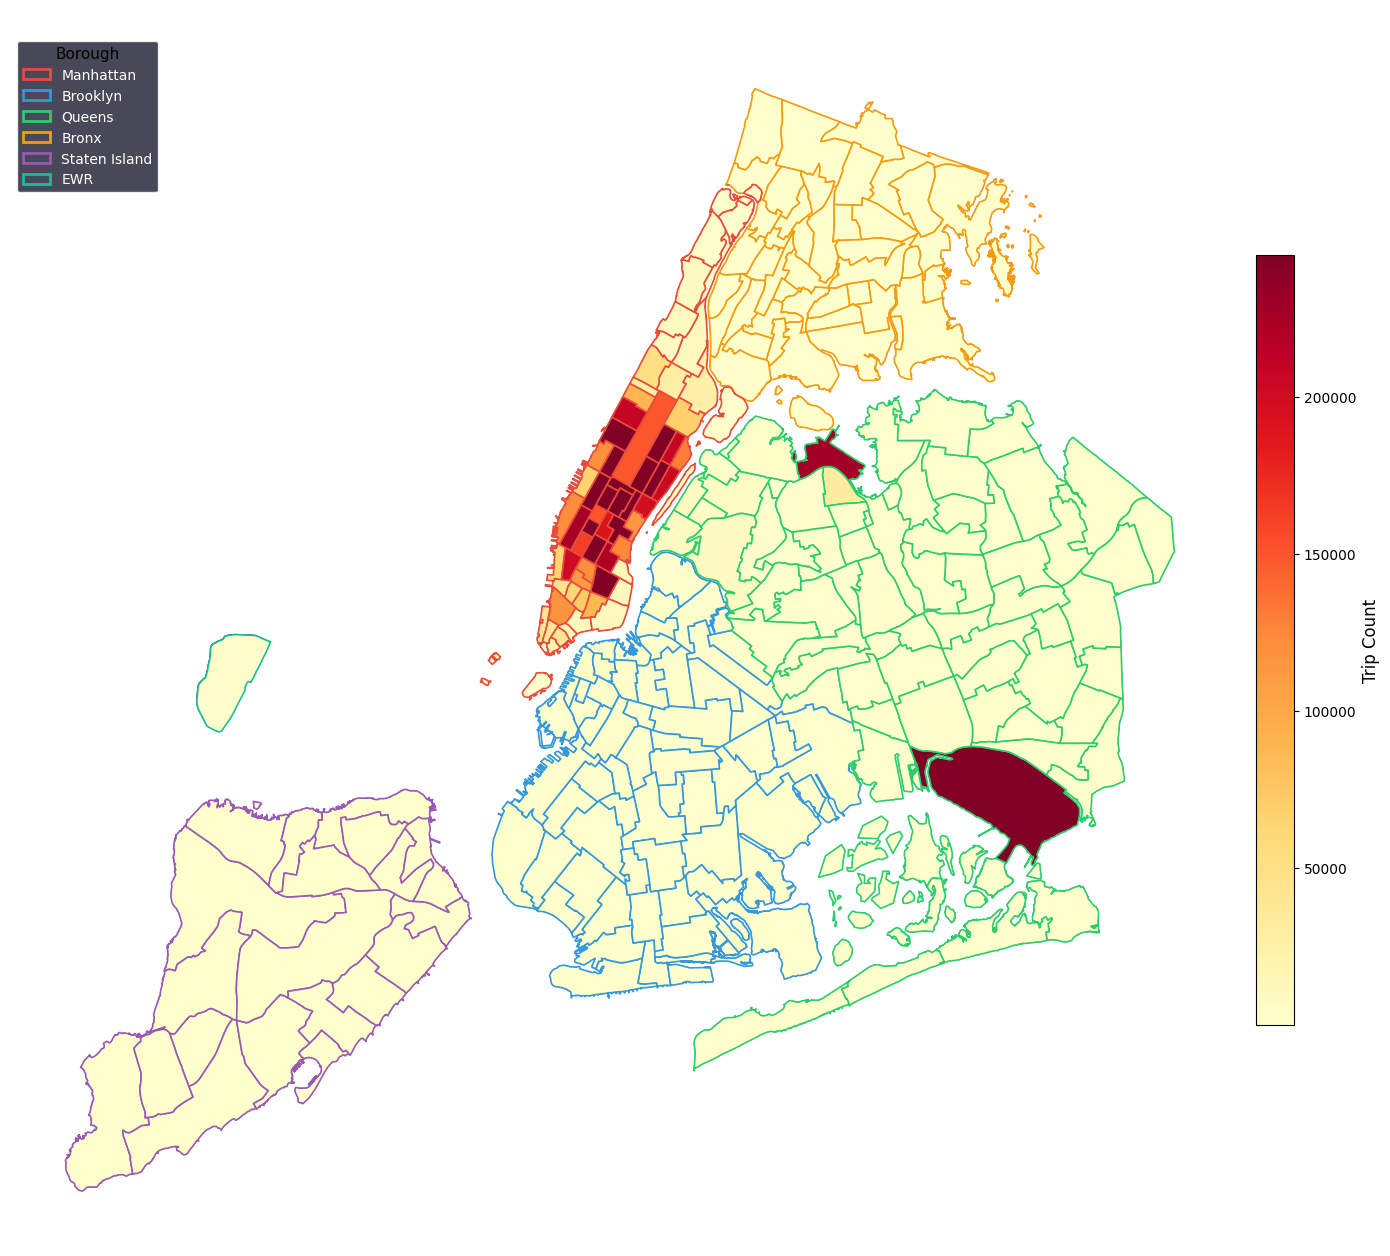

In [11]:
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

def plot_density_map(month_df: dd.DataFrame, location_col: str, title: str) -> None:
    """Plot NYC taxi zone map colored by pickup density with borough boundaries.

    Args:
        month_df: Dask DataFrame with location ID column.
        location_col: Column name for location ID (e.g. "pulocationid").
        title: Plot title.
    """
    # Count trips per zone
    counts = (
        month_df[location_col]
        .value_counts()
        .compute()
        .reset_index()
    )
    counts.columns = ["LocationID", "trip_count"]
    counts["LocationID"] = counts["LocationID"].astype(int)

    # Load zone polygons and merge counts
    zones_gdf = gpd.read_file(SHP_PATH).to_crs("EPSG:4326")
    zones_gdf["LocationID"] = zones_gdf["LocationID"].astype(int)
    zones_gdf = zones_gdf.merge(counts, on="LocationID", how="left")
    zones_gdf["trip_count"] = zones_gdf["trip_count"].fillna(0)

    # Borough edge colors for distinction
    borough_edge_colors = {
        "Manhattan":     "#E74C3C",
        "Brooklyn":      "#3498DB",
        "Queens":        "#2ECC71",
        "Bronx":         "#F39C12",
        "Staten Island": "#9B59B6",
        "EWR":           "#1ABC9C",
    }

    fig, ax = plt.subplots(figsize=(14, 14))
    ax.set_facecolor("#1a1a2e")

    # First pass: draw all zones with a light base fill so every zone is visible
    zones_gdf.plot(ax=ax, color="#2a2a4e", edgecolor="#444444", linewidth=0.4)

    # Second pass: overlay density coloring with borough edges
    vmax = zones_gdf["trip_count"].quantile(0.95)
    for borough, group in zones_gdf.groupby("borough"):
        edge_color = borough_edge_colors.get(borough, "#888888")
        group.plot(
            ax=ax,
            column="trip_count",
            cmap="YlOrRd",
            vmin=1,
            vmax=vmax,
            edgecolor=edge_color,
            linewidth=1.2,
            missing_kwds={"color": "#2a2a4e", "edgecolor": edge_color, "linewidth": 1.2},
        )

    # Colorbar for density
    sm = plt.cm.ScalarMappable(
        cmap="YlOrRd",
        norm=mcolors.Normalize(vmin=1, vmax=vmax),
    )
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Trip Count", fontsize=12)

    # Borough legend
    handles = [
        Patch(facecolor="none", edgecolor=c, linewidth=2, label=b)
        for b, c in borough_edge_colors.items()
    ]
    ax.legend(handles=handles, loc="upper left", fontsize=10, title="Borough",
              facecolor="#1a1a2e", edgecolor="white", labelcolor="white",
              title_fontsize=11)

    ax.set_title(title, fontsize=16, color="white")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


plot_density_map(month, "pulocationid", "Pickup Density by Taxi Zone")

<b>INFERENCE</b>:
The pickup locations seem to be concentrated in the manhattan area

We can see that taxi demand is mostly concentrated in the manhattan area

If the driver/fleet organizer can see this data earlier, then they can strategically put the taxi into the area suspected to be in high demand
<br>**PROBLEM: That is not the case and above data is made from past data**

Therefore, a demand prediction model using pickup as the surrogate value is necessary

Monday -  midnight:49321, morning:310451, afternoon:467619, night:345424
Tuesday -  midnight:41241, morning:350620, afternoon:502814, night:417517
Wednesday -  midnight:48535, morning:353838, afternoon:513831, night:451416
Thursday -  midnight:59751, morning:355791, afternoon:525912, night:488017
Friday -  midnight:82845, morning:295388, afternoon:478586, night:478376
Saturday -  midnight:196307, morning:202905, afternoon:474406, night:456897
Sunday -  midnight:186827, morning:188735, afternoon:446402, night:301435


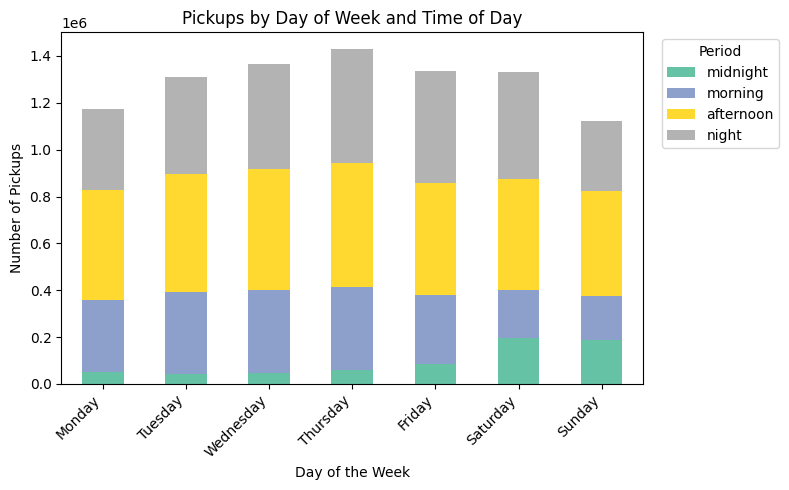

In [12]:
def compute_pickups_per_day() -> pd.DataFrame:
    """Bar chart of pickups by day of week, split into time-of-day periods."""
    # Extract day and hour in Dask, then groupby before computing
    pickup_dt = month[["tpep_pickup_datetime"]]
    pickup_dt["pickup_day"] = pickup_dt["tpep_pickup_datetime"].dt.dayofweek
    pickup_dt["pickup_hour"] = pickup_dt["tpep_pickup_datetime"].dt.hour

    # Aggregate in Dask: count per (day_of_week, hour) — much smaller result
    counts = (
        pickup_dt
        .groupby(["pickup_day", "pickup_hour"])
        .size()
        .reset_index()
        .rename(columns={0: "count"})
        .compute()
    )

    day_labels = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    periods = {
        "midnight":  (0, 6),
        "morning":   (6, 12),
        "afternoon": (12, 18),
        "night":     (18, 24),
    }

    rows = []
    for day_idx, day_name in enumerate(day_labels):
        day_data = counts[counts["pickup_day"] == day_idx]
        row = {}
        for period, (start, end) in periods.items():
            row[period] = day_data[
                (day_data["pickup_hour"] >= start) & (day_data["pickup_hour"] < end)
            ]["count"].sum()
        rows.append(row)
        print(f"{day_name} -  midnight:{row['midnight']}, morning:{row['morning']}, afternoon:{row['afternoon']}, night:{row['night']}")

    days_df = pd.DataFrame(rows, index=day_labels)
    ax = days_df.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2")
    ax.set_xlabel("Day of the Week")
    ax.set_ylabel("Number of Pickups")
    ax.set_title("Pickups by Day of Week and Time of Day")
    ax.set_xticklabels(day_labels, rotation=45, ha="right")
    ax.legend(title="Period", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    return counts

time_df = compute_pickups_per_day()

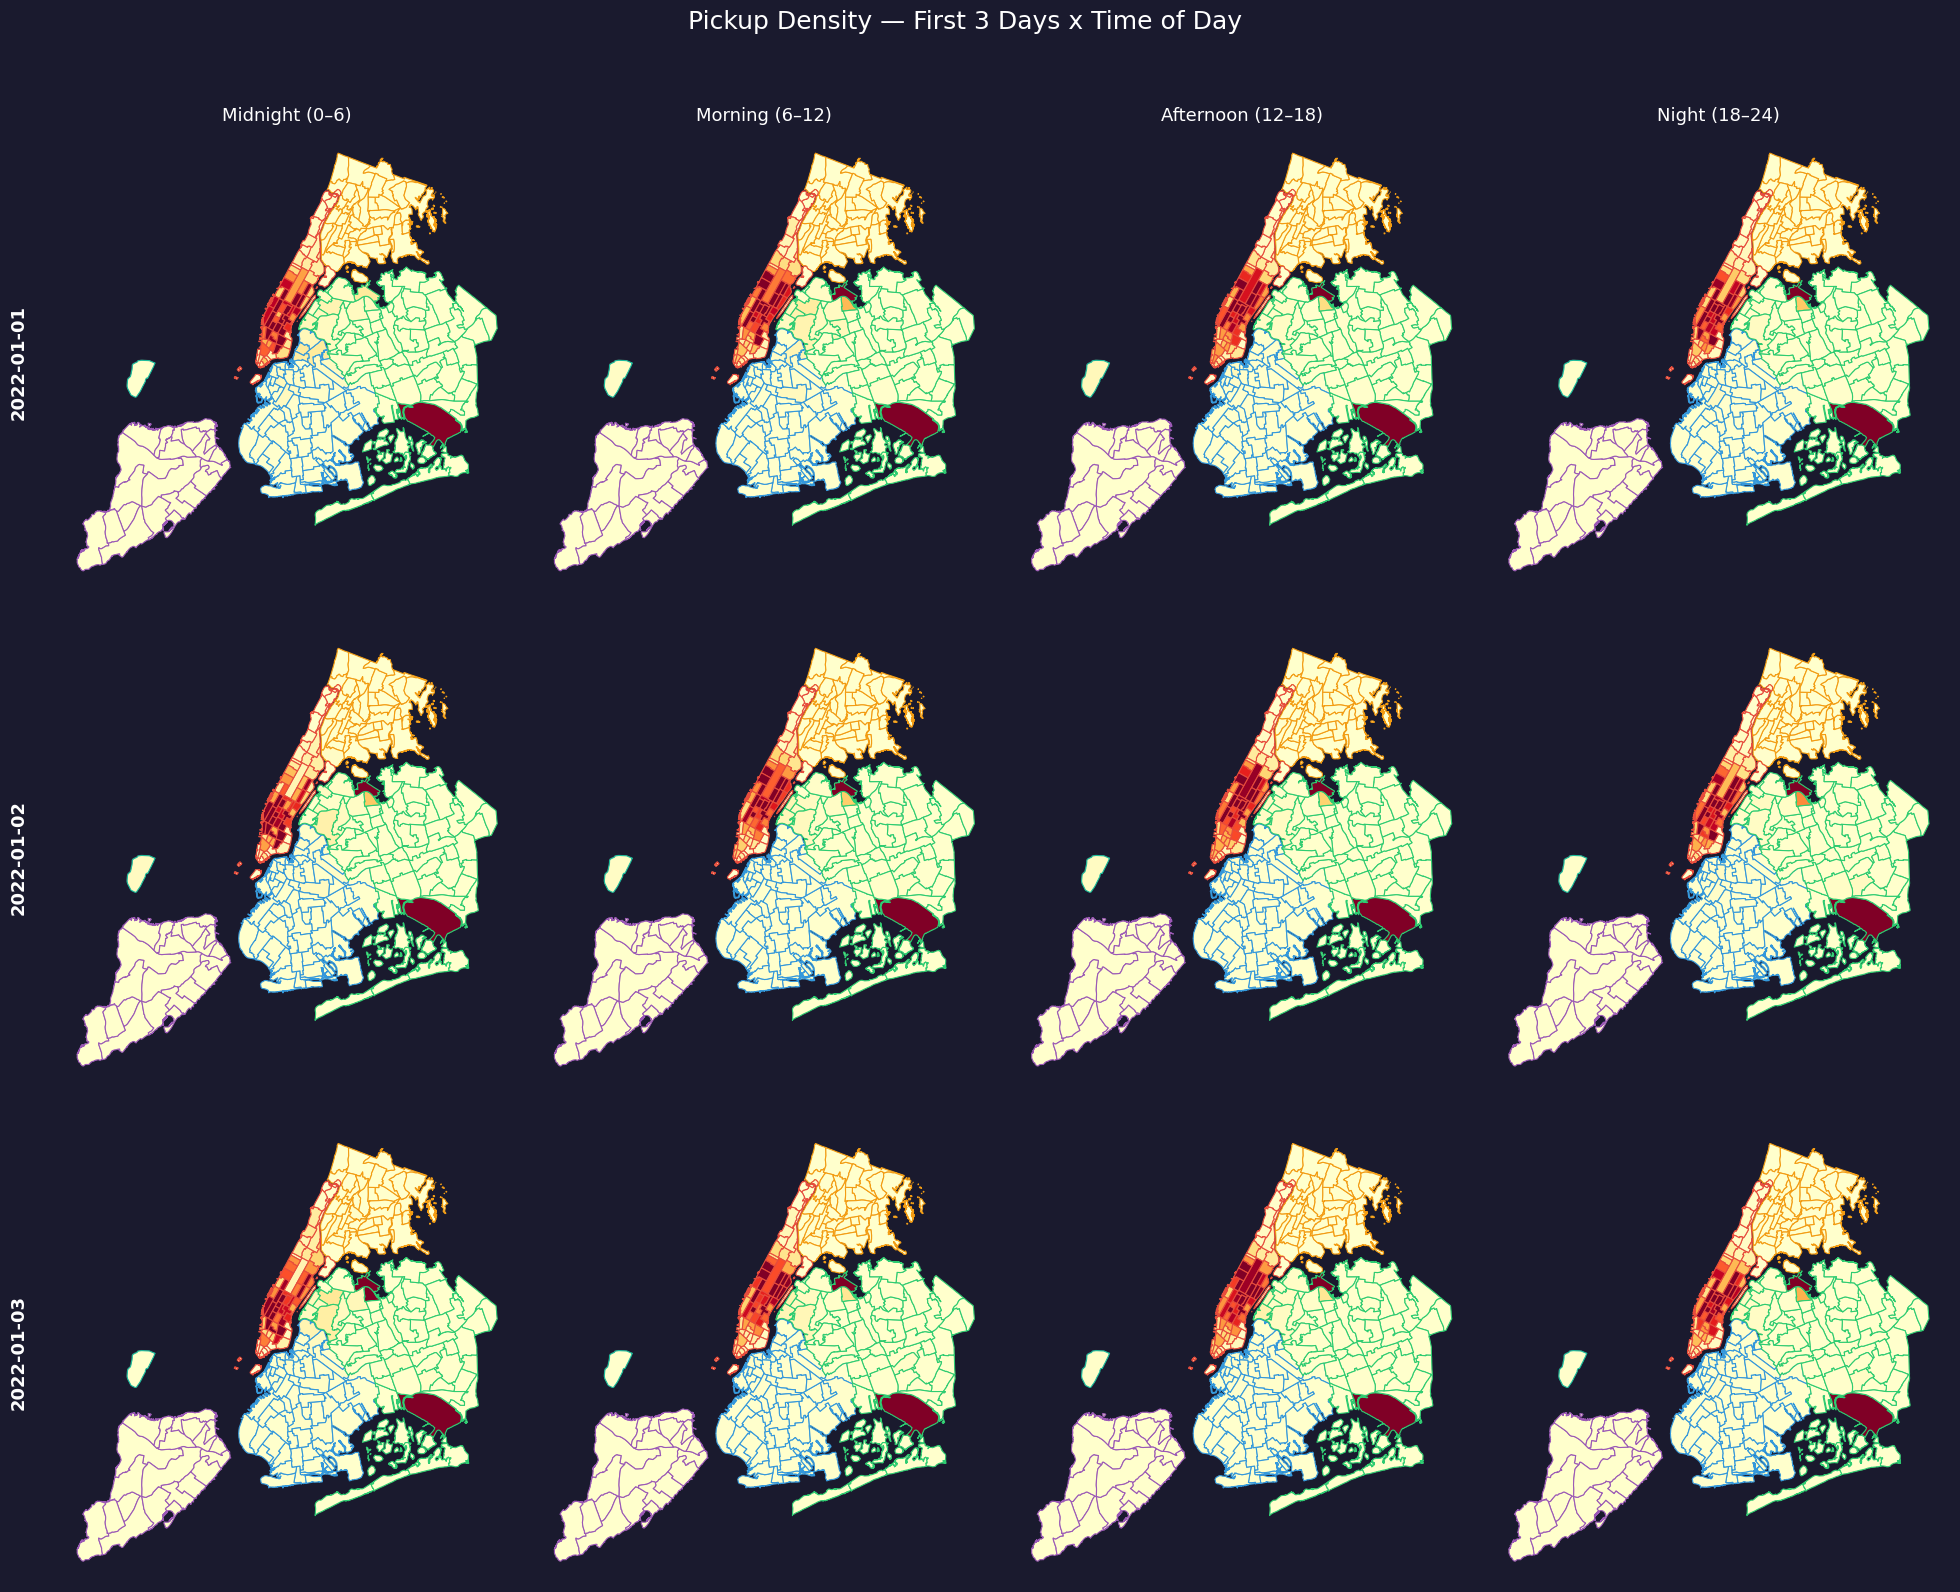

In [15]:
def plot_density_by_day_and_period(month_df: dd.DataFrame, n_days: int = 3) -> None:
    """Plot pickup density maps: one row per day, one column per time period.

    Args:
        month_df: Dask DataFrame with tpep_pickup_datetime and pulocationid.
        n_days: Number of days from the start of the data to include.
    """
    # Compute min date and filter to first N days in Dask before .compute()
    min_date = month_df["tpep_pickup_datetime"].min().compute()
    cutoff = pd.Timestamp(min_date.date()) + pd.Timedelta(days=n_days)
    first_n = month_df[month_df["tpep_pickup_datetime"] < cutoff][["tpep_pickup_datetime", "pulocationid"]]
    pickup_data = first_n.compute()

    pickup_data["date"] = pickup_data["tpep_pickup_datetime"].dt.date
    pickup_data["hour"] = pickup_data["tpep_pickup_datetime"].dt.hour
    days = sorted(pickup_data["date"].unique())[:n_days]

    periods = {
        "Midnight (0–6)":   (0, 6),
        "Morning (6–12)":   (6, 12),
        "Afternoon (12–18)":(12, 18),
        "Night (18–24)":    (18, 24),
    }

    # Load zone polygons once
    zones_gdf = gpd.read_file(SHP_PATH).to_crs("EPSG:4326")
    zones_gdf["LocationID"] = zones_gdf["LocationID"].astype(int)

    borough_edge_colors = {
        "Manhattan":     "#E74C3C",
        "Brooklyn":      "#3498DB",
        "Queens":        "#2ECC71",
        "Bronx":         "#F39C12",
        "Staten Island": "#9B59B6",
        "EWR":           "#1ABC9C",
    }

    n_rows = n_days
    n_cols = len(periods)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5.5 * n_rows))

    for row, day in enumerate(days):
        day_data = pickup_data[pickup_data["date"] == day]

        for col, (period_name, (h_start, h_end)) in enumerate(periods.items()):
            ax = axes[row][col]
            ax.set_facecolor("#1a1a2e")

            # Count pickups for this day + period
            period_data = day_data[(day_data["hour"] >= h_start) & (day_data["hour"] < h_end)]
            counts = period_data.groupby("pulocationid").size().reset_index()
            counts.columns = ["LocationID", "trip_count"]

            gdf = zones_gdf.merge(counts, on="LocationID", how="left")
            gdf["trip_count"] = gdf["trip_count"].fillna(0)
            vmax = max(gdf["trip_count"].quantile(0.95), 1)

            # Base layer
            gdf.plot(ax=ax, color="#2a2a4e", edgecolor="#444444", linewidth=0.3)

            # Density overlay
            for borough, group in gdf.groupby("borough"):
                edge_color = borough_edge_colors.get(borough, "#888888")
                group.plot(
                    ax=ax,
                    column="trip_count",
                    cmap="YlOrRd",
                    vmin=1,
                    vmax=vmax,
                    edgecolor=edge_color,
                    linewidth=0.8,
                    missing_kwds={"color": "#2a2a4e", "edgecolor": edge_color, "linewidth": 0.8},
                )

            ax.set_axis_off()

            # Column headers (period) on top row
            if row == 0:
                ax.set_title(period_name, fontsize=13, color="white", pad=8)

            # Row labels (date) on left column
            if col == 0:
                ax.text(-0.08, 0.5, str(day), transform=ax.transAxes,
                        fontsize=13, color="white", rotation=90,
                        va="center", ha="center", fontweight="bold")

    fig.suptitle(f"Pickup Density — First {n_days} Days x Time of Day",
                 fontsize=18, color="white", y=0.98)
    fig.patch.set_facecolor("#1a1a2e")
    plt.tight_layout(rect=[0.02, 0, 1, 0.96])
    plt.show()


plot_density_by_day_and_period(month, n_days=3)

We also see how the pickup change with hour by making plot of each time-zones in the first 3 days

For the beginning, it will make more sense to make prediction on Manhattan area and Queens area because there are enough signals

### End of EDA

### Data Preprocessing

#### Removing outlier/impossible data

#### Total fare is not removed from outlier

If interviewer asks:

How would you handle outliers?

You can say:

I distinguish between measurement errors (e.g., negative fares, impossible speeds) and rare but valid demand spikes. Only physically impossible values are removed. Operationally significant extremes are preserved.

That shows maturity.

In [11]:
import pandas as pd
import dask.dataframe as dd

# ── NYC bounding box ──────────────────────────────────────────────────────────
NYC_LON_MIN, NYC_LON_MAX = -74.15, -73.7004
NYC_LAT_MIN, NYC_LAT_MAX =  40.5774,  40.9176


def remove_location_outliers(df: dd.DataFrame) -> dd.DataFrame:
    """Filter out pickups outside the NYC bounding box.

    Args:
        df: Dask DataFrame with pickup_longitude and pickup_latitude columns.

    Returns:
        Filtered Dask DataFrame.
    """
    return df[
        (df.pickup_longitude > NYC_LON_MIN) &
        (df.pickup_longitude < NYC_LON_MAX) &
        (df.pickup_latitude  > NYC_LAT_MIN) &
        (df.pickup_latitude  < NYC_LAT_MAX)
    ]


def remove_negative_duration(df: dd.DataFrame) -> dd.DataFrame:
    """Remove rows where dropoff is before pickup (impossible trips).

    Args:
        df: Dask DataFrame with tpep_pickup_datetime and tpep_dropoff_datetime.

    Returns:
        Filtered Dask DataFrame.
    """
    return df[df["tpep_dropoff_datetime"] > df["tpep_pickup_datetime"]]


def run_outlier_pipeline(df: dd.DataFrame) -> dd.DataFrame:
    """Run the outlier removal pipeline.

    Steps:
        1. Map pickup coordinates from taxi zone shapefile.
        2. Remove pickups outside the NYC bounding box.
        3. Remove rows with negative trip duration (corrupt records).

    Args:
        df: Dask DataFrame from the bronze parquet.

    Returns:
        Clean Dask DataFrame ready for feature engineering.
    """
    df = add_pickup_coords(df, SHP_PATH)
    df = remove_location_outliers(df)
    df = remove_negative_duration(df)
    return df


# ── Run ───────────────────────────────────────────────────────────────────────
clean_df = run_outlier_pipeline(month)
print(f"Rows after outlier removal: {len(clean_df):,}")
clean_df.head()

/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that you are using.
  Before: .map(func)
  After:  .map(func, meta=('pulocationid', 'float64'))

  warnings.warn(meta_warning(meta, method="map"))
/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that yo

Rows after outlier removal: 8,953,548


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_zone,pickup_borough,dropoff_zone,dropoff_borough,pickup_longitude,pickup_latitude
0,2,2022-01-01 00:00:08,2022-01-01 00:14:14,1,7.94,1,N,138,255,1,...,0.3,30.410000,0.0,1.25,LaGuardia Airport,Queens,Williamsburg (North Side),Brooklyn,-73.873629,40.774376
1,2,2022-01-01 00:00:11,2022-01-01 00:14:29,1,5.55,1,N,132,215,2,...,0.3,20.049999,0.0,1.25,JFK Airport,Queens,South Jamaica,Queens,-73.786535,40.646987
2,2,2022-01-01 00:00:17,2022-01-01 00:31:04,1,3.86,1,N,170,68,1,...,0.3,28.559999,2.5,0.0,Murray Hill,Manhattan,East Chelsea,Manhattan,-73.978492,40.747746
3,2,2022-01-01 00:00:18,2022-01-01 00:13:27,1,3.37,1,N,79,209,1,...,0.3,20.160000,2.5,0.0,East Village,Manhattan,Seaport,Manhattan,-73.985937,40.727620
4,2,2022-01-01 00:00:20,2022-01-01 00:20:51,1,4.89,1,N,68,256,1,...,0.3,28.340000,2.5,0.0,East Chelsea,Manhattan,Williamsburg (South Side),Brooklyn,-73.999917,40.748428


In [12]:
def build_hourly_demand(
    df: dd.DataFrame,
    zone_col: str = "pulocationid",
    datetime_col: str = "tpep_pickup_datetime",
) -> pd.DataFrame:
    """Aggregate trip data into (zone, hour) -> trip_count panel.

    Creates a complete grid of all zones x all hours in the date range,
    filling missing combinations with 0.

    Args:
        df: Dask DataFrame with at least zone and datetime columns.
        zone_col: Column name for the taxi zone ID.
        datetime_col: Column name for the pickup datetime.

    Returns:
        pandas DataFrame with columns:
            - pulocationid: taxi zone ID
            - hour: hourly timestamp (floor)
            - trip_count: number of pickups (0 if none)
    """
    # Aggregate in Dask — only the small result is computed into pandas
    grouped = df.assign(hour=df[datetime_col].dt.floor("h"))
    trip_counts = (
        grouped.groupby([zone_col, "hour"])
        .size()
        .rename("trip_count")
        .reset_index()
        .compute()
    )

    # Build the complete grid: every zone x every hour
    all_zones = sorted(trip_counts[zone_col].unique())
    all_hours = pd.date_range(
        start=trip_counts["hour"].min(),
        end=trip_counts["hour"].max(),
        freq="h",
    )
    full_grid = pd.MultiIndex.from_product(
        [all_zones, all_hours], names=[zone_col, "hour"]
    ).to_frame(index=False)

    # Merge and fill missing with 0
    result = full_grid.merge(trip_counts, on=[zone_col, "hour"], how="left")
    result["trip_count"] = result["trip_count"].fillna(0).astype(int)

    print(f"Zones: {len(all_zones)}")
    print(f"Hours: {len(all_hours)}")
    print(f"Total rows (zones x hours): {len(result):,}")
    print(f"Non-zero rows: {(result['trip_count'] > 0).sum():,} "
          f"({(result['trip_count'] > 0).mean():.1%})")

    return result


hourly_demand_panel = build_hourly_demand(month)
hourly_demand_panel.head(10)

Zones: 260
Hours: 2160
Total rows (zones x hours): 561,600
Non-zero rows: 204,599 (36.4%)


,pulocationid,hour,trip_count
0,1,2022-01-01 00:00:00,0
1,1,2022-01-01 01:00:00,0
2,1,2022-01-01 02:00:00,0
3,1,2022-01-01 03:00:00,0
4,1,2022-01-01 04:00:00,1
5,1,2022-01-01 05:00:00,1
6,1,2022-01-01 06:00:00,0
7,1,2022-01-01 07:00:00,2
8,1,2022-01-01 08:00:00,0
9,1,2022-01-01 09:00:00,0


In [13]:
def add_time_features(df: pd.DataFrame, hour_col: str = "hour") -> pd.DataFrame:
    """Add temporal features derived from the hour column.

    Args:
        df: DataFrame with an hourly timestamp column.
        hour_col: Name of the datetime column.

    Returns:
        DataFrame with new columns: hour_of_day, day_of_week, month.
    """
    df = df.copy()
    df["hour_of_day"] = df[hour_col].dt.hour
    df["day_of_week"] = df[hour_col].dt.dayofweek   # 0=Mon, 6=Sun
    df["month"] = df[hour_col].dt.month
    return df


hourly_demand_panel = add_time_features(hourly_demand_panel)
hourly_demand_panel.head(10)

,pulocationid,hour,trip_count,hour_of_day,day_of_week,month
0,1,2022-01-01 00:00:00,0,0,5,1
1,1,2022-01-01 01:00:00,0,1,5,1
2,1,2022-01-01 02:00:00,0,2,5,1
3,1,2022-01-01 03:00:00,0,3,5,1
4,1,2022-01-01 04:00:00,1,4,5,1
5,1,2022-01-01 05:00:00,1,5,5,1
6,1,2022-01-01 06:00:00,0,6,5,1
7,1,2022-01-01 07:00:00,2,7,5,1
8,1,2022-01-01 08:00:00,0,8,5,1
9,1,2022-01-01 09:00:00,0,9,5,1


In [14]:
def add_cyclical_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add sine/cosine encoding for cyclical time features.

    Encodes hour_of_day (period=24), day_of_week (period=7),
    and month (period=12) as sin/cos pairs so the model understands
    that e.g. hour 23 and hour 0 are adjacent.

    Args:
        df: DataFrame with hour_of_day, day_of_week, and month columns.

    Returns:
        DataFrame with 6 new columns: *_sin and *_cos for each feature.
    """
    df = df.copy()
    cyclical = {
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
    }
    for col, period in cyclical.items():
        df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / period)
        df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / period)
    return df


hourly_demand_panel = add_cyclical_features(hourly_demand_panel)
hourly_demand_panel[["hour_of_day", "hour_of_day_sin", "hour_of_day_cos",
                     "day_of_week", "day_of_week_sin", "day_of_week_cos",
                     "month", "month_sin", "month_cos"]].head(10)

,hour_of_day,hour_of_day_sin,hour_of_day_cos,day_of_week,day_of_week_sin,day_of_week_cos,month,month_sin,month_cos
0,0,0.000000,1.000000e+00,5,-0.974928,-0.222521,1,0.5,0.866025
1,1,0.258819,9.659258e-01,5,-0.974928,-0.222521,1,0.5,0.866025
2,2,0.500000,8.660254e-01,5,-0.974928,-0.222521,1,0.5,0.866025
3,3,0.707107,7.071068e-01,5,-0.974928,-0.222521,1,0.5,0.866025
4,4,0.866025,5.000000e-01,5,-0.974928,-0.222521,1,0.5,0.866025
5,5,0.965926,2.588190e-01,5,-0.974928,-0.222521,1,0.5,0.866025
6,6,1.000000,6.123234e-17,5,-0.974928,-0.222521,1,0.5,0.866025
7,7,0.965926,-2.588190e-01,5,-0.974928,-0.222521,1,0.5,0.866025
8,8,0.866025,-5.000000e-01,5,-0.974928,-0.222521,1,0.5,0.866025
9,9,0.707107,-7.071068e-01,5,-0.974928,-0.222521,1,0.5,0.866025


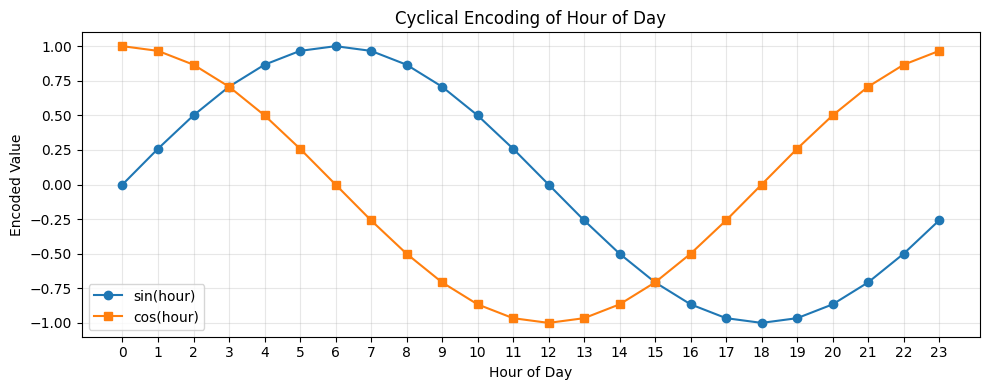

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
hours = np.arange(24)
ax.plot(hours, np.sin(2 * np.pi * hours / 24), marker="o", label="sin(hour)")
ax.plot(hours, np.cos(2 * np.pi * hours / 24), marker="s", label="cos(hour)")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Encoded Value")
ax.set_title("Cyclical Encoding of Hour of Day")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
def add_zone_coords(
    df: pd.DataFrame,
    shp_path: str = SHP_PATH,
    zone_col: str = "pulocationid",
    prefix: str = "pickup",
) -> pd.DataFrame:
    """Map zone ID to centroid longitude and latitude.

    Args:
        df: DataFrame with a zone ID column.
        shp_path: Path to the taxi_zones.shp file.
        zone_col: Column name for the zone ID.

    Returns:
        DataFrame with new columns: longitude, latitude.
    """
    lookup = build_zone_lookup(shp_path)
    lon_map = lookup.set_index("LocationID")["longitude"]
    lat_map = lookup.set_index("LocationID")["latitude"]

    df = df.copy()
    df[f"{prefix}_longitude"] = df[zone_col].map(lon_map)
    df[f"{prefix}_latitude"] = df[zone_col].map(lat_map)
    return df


hourly_demand_panel = add_zone_coords(hourly_demand_panel)
hourly_demand_panel[["pulocationid", "pickup_longitude", "pickup_latitude"]].groupby("pulocationid").first().head(10)

,pickup_longitude,pickup_latitude
pulocationid,,
1,-74.174000,40.691833
2,-73.831298,40.616749
3,-73.847422,40.864474
4,-73.976968,40.723752
5,-74.188484,40.552660
6,-74.071771,40.600325
7,-73.919694,40.761493
8,-73.923086,40.778559
9,-73.787949,40.751036


In [17]:
import yaml

with open("../config.yml") as f:
    cfg = yaml.safe_load(f)

LAG_HOURS: list[int] = cfg["feature"]["lag_hours"]


def add_lag_features(
    df: pd.DataFrame,
    lag_hours: list[int],
    zone_col: str = "pulocationid",
    target_col: str = "trip_count",
) -> pd.DataFrame:
    """Add lagged pickup count columns per zone.

    For each value in ``lag_hours``, creates a column
    ``trip_count_lag_{h}`` containing the pickup count
    ``h`` hours earlier for the same zone.

    The DataFrame must be sorted by (zone, hour) and contain
    a complete hourly grid so that a simple ``shift(h)`` within
    each zone group produces the correct lag.

    Args:
        df: DataFrame with zone ID, hour, and trip_count columns.
        lag_hours: List of lag offsets in hours (e.g. [1, 3, 6, 12, 24]).
        zone_col: Column name for the zone ID.
        target_col: Column name for the pickup count.

    Returns:
        DataFrame with new lag columns. Rows where any lag is NaN
        (i.e. the first ``max(lag_hours)`` rows per zone) are dropped.
    """
    df = df.sort_values([zone_col, "hour"]).copy()
    for h in lag_hours:
        df[f"{target_col}_lag_{h}"] = df.groupby(zone_col)[target_col].shift(h)

    n_before = len(df)
    df = df.dropna(subset=[f"{target_col}_lag_{h}" for h in lag_hours])
    # Cast back to int after dropna
    for h in lag_hours:
        df[f"{target_col}_lag_{h}"] = df[f"{target_col}_lag_{h}"].astype(int)

    print(f"Lag hours: {lag_hours}")
    print(f"Rows dropped (insufficient history): {n_before - len(df):,}")
    print(f"Rows remaining: {len(df):,}")
    return df


hourly_demand_panel = add_lag_features(hourly_demand_panel, LAG_HOURS)
lag_cols = ["hour", "trip_count"] + [f"trip_count_lag_{h}" for h in LAG_HOURS]
hourly_demand_panel[hourly_demand_panel["pulocationid"] == 161][lag_cols].head(10)

Lag hours: [1, 3, 6, 12, 24]
Rows dropped (insufficient history): 6,240
Rows remaining: 555,360


,hour,trip_count,trip_count_lag_1,trip_count_lag_3,trip_count_lag_6,trip_count_lag_12,trip_count_lag_24
339144,2022-01-02 00:00:00,25,58,79,154,129,133
339145,2022-01-02 01:00:00,7,25,60,136,148,160
339146,2022-01-02 02:00:00,3,7,58,93,144,105
339147,2022-01-02 03:00:00,2,3,25,79,130,27
339148,2022-01-02 04:00:00,2,2,7,60,146,39
339149,2022-01-02 05:00:00,3,2,3,58,177,12
339150,2022-01-02 06:00:00,8,3,2,25,154,11
339151,2022-01-02 07:00:00,17,8,2,7,136,13
339152,2022-01-02 08:00:00,34,17,3,3,93,24
339153,2022-01-02 09:00:00,43,34,8,2,79,42


### Baseline Models: Seasonal Naive

**Goal:** Predict `trip_count` at time *t* for each zone using seasonal naive baselines.

**Approach (following Pranshu):** No train/test split. For each hour *t* that has
enough history, predict using past same-hour values and evaluate the error immediately.
The MA "trains" itself by looking back at recent data — no held-out set needed.

**Two naive baselines:**
1. **Same Hour Yesterday (t−24):** demand today at 9AM ≈ demand yesterday at 9AM
2. **Same Hour Last Week (t−168):** demand this Tuesday at 9AM ≈ demand last Tuesday at 9AM

**Evaluation:** computed over all predictions that have sufficient history

In [41]:
ZONE_COL = "pulocationid"
TARGET = "trip_count"

# ── 1. January 2022 hourly demand ──────────────────────────────────────────
demand_jan = hourly_demand_panel[
    (hourly_demand_panel["hour"] >= "2022-01-01") &
    (hourly_demand_panel["hour"] < "2022-02-01")
].copy()
demand_jan = demand_jan.sort_values([ZONE_COL, "hour"]).reset_index(drop=True)
print(f"Jan 2022 hourly demand: {len(demand_jan):,} rows")

# ── 2. Build seasonal naive lags (per zone) ────────────────────────────────
demand_jan["pred_yesterday"] = demand_jan.groupby(ZONE_COL)[TARGET].shift(24)
demand_jan["pred_last_week"] = demand_jan.groupby(ZONE_COL)[TARGET].shift(168)

# Keep rows with enough history (7 days for weekly lag)
df_eval = demand_jan.dropna(subset=["pred_yesterday", "pred_last_week"]).copy()
print(f"Rows with full 7-day history: {len(df_eval):,}")
print(f"Date range: {df_eval['hour'].min()} → {df_eval['hour'].max()}")

# ── 3. Evaluate over ALL rows (no train/test split) ───────────────────────
actual = df_eval[TARGET].values
mask = actual > 0
actual_mean = actual.mean()

results: list[dict] = []
for name, col in [("Same Hour Yesterday (t-24)", "pred_yesterday"),
                  ("Same Hour Last Week (t-168)", "pred_last_week")]:
    pred = df_eval[col].values
    mae = np.abs(actual - pred).mean()
    rmse = np.sqrt(((actual - pred) ** 2).mean())
    mape = (np.abs(actual[mask] - pred[mask]) / actual[mask]).mean() * 100
    wape = (mae / actual_mean) * 100
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "MAPE%": mape, "WAPE%": wape})

results_df = pd.DataFrame(results).round(2)
print("\n=== Seasonal Naive Baselines (Jan 2022) ===\n")
print(results_df.to_string(index=False))
print("\nMAPE% = mean(|error_i| / actual_i) — per-row, sensitive to low-traffic zones")
print("WAPE% = MAE / mean(actual)          — Pranshu's formula, robust to near-zero values")

Jan 2022 hourly demand: 187,200 rows
Rows with full 7-day history: 143,520
Date range: 2022-01-09 00:00:00 → 2022-01-31 23:00:00

=== Seasonal Naive Baselines (Jan 2022) ===

                      model  MAE  RMSE  MAPE%  WAPE%
 Same Hour Yesterday (t-24) 4.41 16.97  79.47  33.55
Same Hour Last Week (t-168) 3.31 12.54  60.53  25.18

MAPE% = mean(|error_i| / actual_i) — per-row, sensitive to low-traffic zones
WAPE% = MAE / mean(actual)          — Pranshu's formula, robust to near-zero values


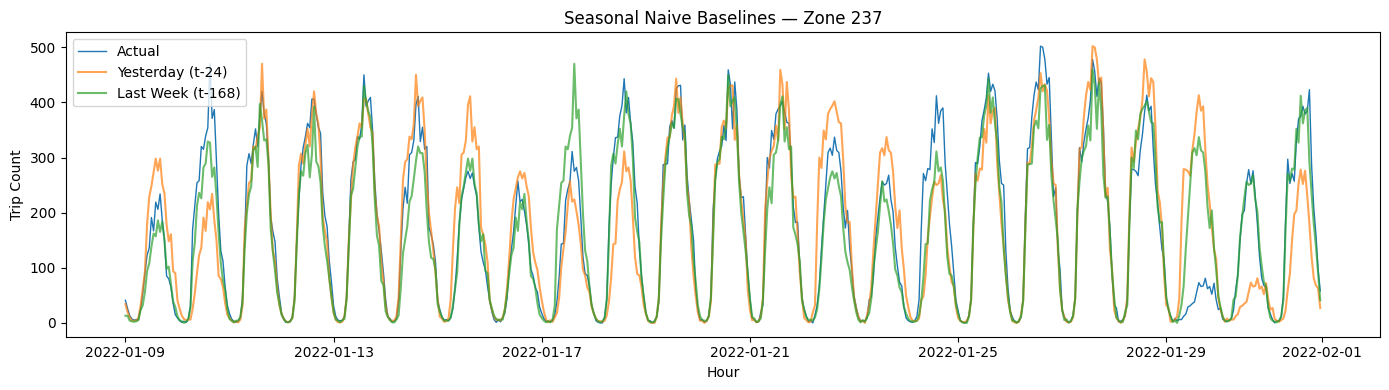

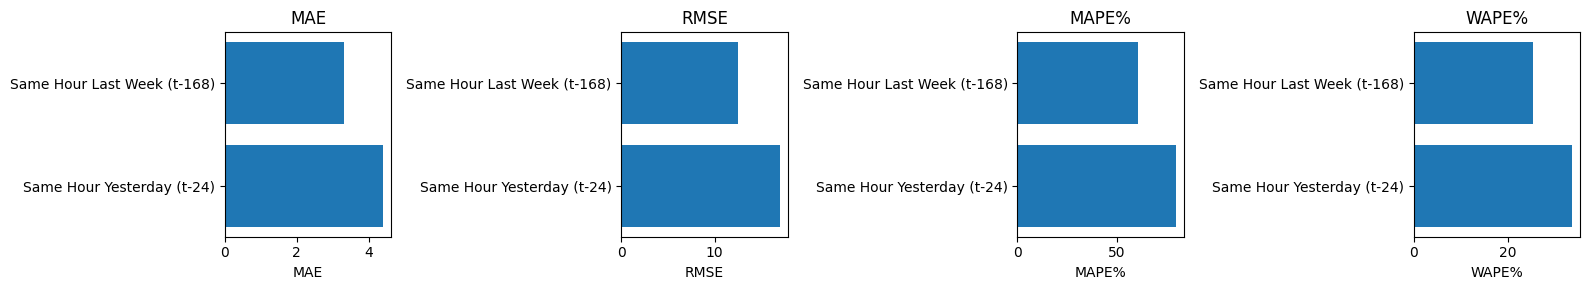

In [42]:
# ── Visualise: actual vs predicted for a sample zone ────────────────────────
import matplotlib.pyplot as plt

# Rebuild seasonal naive predictions for plotting (df_eval was overwritten by MA cell)
plot_jan = demand_jan.dropna(subset=["pred_yesterday", "pred_last_week"]).copy()

# Pick a high-traffic zone for visual clarity
zone_counts = plot_jan.groupby(ZONE_COL)[TARGET].mean().sort_values(ascending=False)
sample_zone = zone_counts.index[0]
zone_data = plot_jan[plot_jan[ZONE_COL] == sample_zone].copy()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(zone_data["hour"], zone_data[TARGET], label="Actual", linewidth=1)
ax.plot(zone_data["hour"], zone_data["pred_yesterday"], label="Yesterday (t-24)", alpha=0.7)
ax.plot(zone_data["hour"], zone_data["pred_last_week"], label="Last Week (t-168)", alpha=0.7)
ax.set_xlabel("Hour")
ax.set_ylabel("Trip Count")
ax.set_title(f"Seasonal Naive Baselines — Zone {sample_zone}")
ax.legend()
plt.tight_layout()
plt.show()

# ── Bar chart comparison ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE%", "WAPE%"]):
    ax.barh(results_df["model"], results_df[metric])
    ax.set_xlabel(metric)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

### Baseline Models: Same-Hour MA (Daily & Weekly Lags)

**Problem with consecutive hourly lags:** Averaging t-1, t-2, …, t-w mixes different
times of day (3AM with 8AM), degrading predictions as the window grows.

**Fix:** Use **same-hour lags** so that each lag compares like with like:

**Daily lags** — for predicting zone 161 at Tuesday 8AM:
- `lag_1d` = Monday 8AM, `lag_2d` = Sunday 8AM, …, `lag_6d` = last Wednesday 8AM
- Window sizes: `[1, 3, 6, 12, 24]` days

**Weekly lags** — for predicting zone 161 at Tuesday 8AM:
- `lag_1w` = last Tuesday 8AM, `lag_2w` = two Tuesdays ago 8AM, …
- Window sizes: `[1, 2, 3]` weeks (limited by January = ~4 weeks)

**Two variants per model:**
- **Value:** MA applied directly on raw `trip_count` lags
- **Ratio:** MA applied on `R_t = trip_count_2022 / trip_count_2021`, then `pred = given_2021 × predicted_R`

**Three MA models:** SMA, WMA, EMA (same as before)

In [37]:
DAILY_WINDOWS = [1, 3, 6, 12, 24]
WEEKLY_WINDOWS = [1, 2, 3]

# ── 1. Load January 2021 baseline for ratio computation ────────────────────
baseline_raw = dd.read_parquet("../data/bronze/2021_01/2021_01.parquet")
baseline_raw = baseline_raw[
    (baseline_raw["tpep_pickup_datetime"] >= "2021-01-01") &
    (baseline_raw["tpep_pickup_datetime"] < "2021-02-01")
]
demand_2021 = build_hourly_demand(baseline_raw, zone_col=ZONE_COL)
demand_2021["day"] = demand_2021["hour"].dt.day
demand_2021["hour_of_day"] = demand_2021["hour"].dt.hour
print(f"2021 Jan hourly demand: {len(demand_2021):,} rows")

# ── 2. January 2022 + align with 2021 for ratios ──────────────────────────
demand_jan = hourly_demand_panel[
    (hourly_demand_panel["hour"] >= "2022-01-01") &
    (hourly_demand_panel["hour"] < "2022-02-01")
].copy()
demand_jan = demand_jan.sort_values([ZONE_COL, "hour"]).reset_index(drop=True)
demand_jan["day"] = demand_jan["hour"].dt.day
demand_jan["hour_of_day"] = demand_jan["hour"].dt.hour

aligned = demand_jan.merge(
    demand_2021[[ZONE_COL, "day", "hour_of_day", TARGET]].rename(
        columns={TARGET: "given"}
    ),
    on=[ZONE_COL, "day", "hour_of_day"],
    how="inner",
)
aligned["ratio"] = np.where(
    aligned["given"] > 0,
    aligned[TARGET] / aligned["given"],
    np.nan,
)
# Sort by [zone, hour] for correct per-zone shift
aligned = aligned.sort_values([ZONE_COL, "hour"]).reset_index(drop=True)
print(f"Aligned rows: {len(aligned):,}")

# ── 3. Build same-hour DAILY lags (shift by 24*k per zone) ────────────────
max_daily = max(DAILY_WINDOWS)
for k in range(1, max_daily + 1):
    aligned[f"val_d{k}"] = aligned.groupby(ZONE_COL)[TARGET].shift(24 * k)
    aligned[f"rat_d{k}"] = aligned.groupby(ZONE_COL)["ratio"].shift(24 * k)

# ── 4. Build same-hour WEEKLY lags (shift by 168*k per zone) ──────────────
max_weekly = max(WEEKLY_WINDOWS)
for k in range(1, max_weekly + 1):
    aligned[f"val_w{k}"] = aligned.groupby(ZONE_COL)[TARGET].shift(168 * k)
    aligned[f"rat_w{k}"] = aligned.groupby(ZONE_COL)["ratio"].shift(168 * k)

# ── 5. Helper: compute SMA, WMA, EMA predictions from lag matrix ──────────
def compute_ma_predictions(
    lags: np.ndarray, w: int
) -> dict[str, np.ndarray]:
    """Return SMA, WMA, EMA predictions from a (n_samples, w) lag matrix."""
    sma = lags.mean(axis=1)

    weights = np.arange(w, 0, -1, dtype=float)
    wma = (lags * weights).sum(axis=1) / weights.sum()

    alpha = 2.0 / (w + 1)
    ema = lags[:, -1].astype(float).copy()
    for i in range(w - 2, -1, -1):
        ema = alpha * lags[:, i] + (1 - alpha) * ema

    return {"SMA": sma, "WMA": wma, "EMA": ema}


def evaluate(
    actual: np.ndarray, pred: np.ndarray, mask: np.ndarray,
    actual_mean: float,
) -> dict[str, float]:
    """Return MAE, RMSE, MAPE, WAPE."""
    mae = np.abs(actual - pred).mean()
    return {
        "MAE": mae,
        "RMSE": np.sqrt(((actual - pred) ** 2).mean()),
        "MAPE%": (np.abs(actual[mask] - pred[mask]) / actual[mask]).mean() * 100,
        "WAPE%": (mae / actual_mean) * 100,
    }

# ── 6. Evaluate all configurations (no train/test split) ──────────────────

# Drop rows needing most history (weekly w=3 → 504h)
all_lag_cols = (
    [f"val_d{k}" for k in range(1, max_daily + 1)]
    + [f"rat_d{k}" for k in range(1, max_daily + 1)]
    + [f"val_w{k}" for k in range(1, max_weekly + 1)]
    + [f"rat_w{k}" for k in range(1, max_weekly + 1)]
)
df_eval = aligned.dropna(subset=all_lag_cols).copy()
print(f"Rows with full history: {len(df_eval):,}")
print(f"Date range: {df_eval['hour'].min()} → {df_eval['hour'].max()}")

actual = df_eval[TARGET].values
given = df_eval["given"].values
mask = actual > 0
actual_mean = actual.mean()

results: list[dict] = []

# --- Daily-lag MA models ---
for w in DAILY_WINDOWS:
    val_cols = [f"val_d{k}" for k in range(1, w + 1)]
    rat_cols = [f"rat_d{k}" for k in range(1, w + 1)]

    for variant, cols in [("value", val_cols), ("ratio", rat_cols)]:
        lags = df_eval[cols].values
        preds = compute_ma_predictions(lags, w)
        for model_name, pred_raw in preds.items():
            pred = given * pred_raw if variant == "ratio" else pred_raw
            metrics = evaluate(actual, pred, mask, actual_mean)
            results.append({
                "lag_type": "daily", "model": model_name, "variant": variant,
                "window": f"{w}d", **metrics,
            })

# --- Weekly-lag MA models ---
for w in WEEKLY_WINDOWS:
    val_cols = [f"val_w{k}" for k in range(1, w + 1)]
    rat_cols = [f"rat_w{k}" for k in range(1, w + 1)]

    for variant, cols in [("value", val_cols), ("ratio", rat_cols)]:
        lags = df_eval[cols].values
        preds = compute_ma_predictions(lags, w)
        for model_name, pred_raw in preds.items():
            pred = given * pred_raw if variant == "ratio" else pred_raw
            metrics = evaluate(actual, pred, mask, actual_mean)
            results.append({
                "lag_type": "weekly", "model": model_name, "variant": variant,
                "window": f"{w}w", **metrics,
            })

ma_results_df = pd.DataFrame(results).round(2)
print("\n=== Same-Hour MA Baselines (Jan 2022) ===\n")
print(ma_results_df.to_string(index=False))

Zones: 258
Hours: 744
Total rows (zones x hours): 191,952
Non-zero rows: 80,938 (42.2%)
2021 Jan hourly demand: 191,952 rows
Aligned rows: 185,040
Rows with full history: 6,408
Date range: 2022-01-26 00:00:00 → 2022-01-31 23:00:00

=== Same-Hour MA Baselines (Jan 2022) ===

lag_type model variant window   MAE  RMSE  MAPE%  WAPE%
   daily   SMA   value     1d 28.77 50.97 110.48  40.79
   daily   WMA   value     1d 28.77 50.97 110.48  40.79
   daily   EMA   value     1d 28.77 50.97 110.48  40.79
   daily   SMA   ratio     1d 37.39 62.86 132.33  53.01
   daily   WMA   ratio     1d 37.39 62.86 132.33  53.01
   daily   EMA   ratio     1d 37.39 62.86 132.33  53.01
   daily   SMA   value     3d 28.65 50.15 116.33  40.63
   daily   WMA   value     3d 27.59 49.08 112.54  39.12
   daily   EMA   value     3d 27.35 48.50 112.22  38.78
   daily   SMA   ratio     3d 43.23 79.50 148.96  61.30
   daily   WMA   ratio     3d 40.95 72.14 142.75  58.06
   daily   EMA   ratio     3d 40.67 71.62 142.48  57.

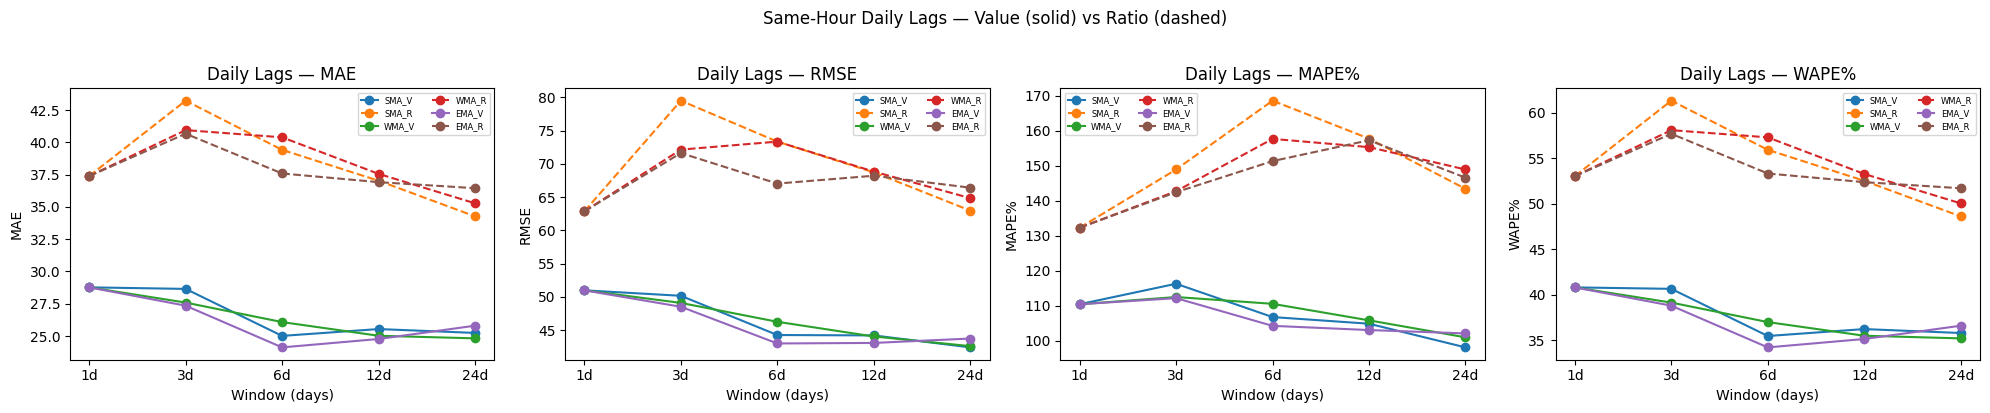

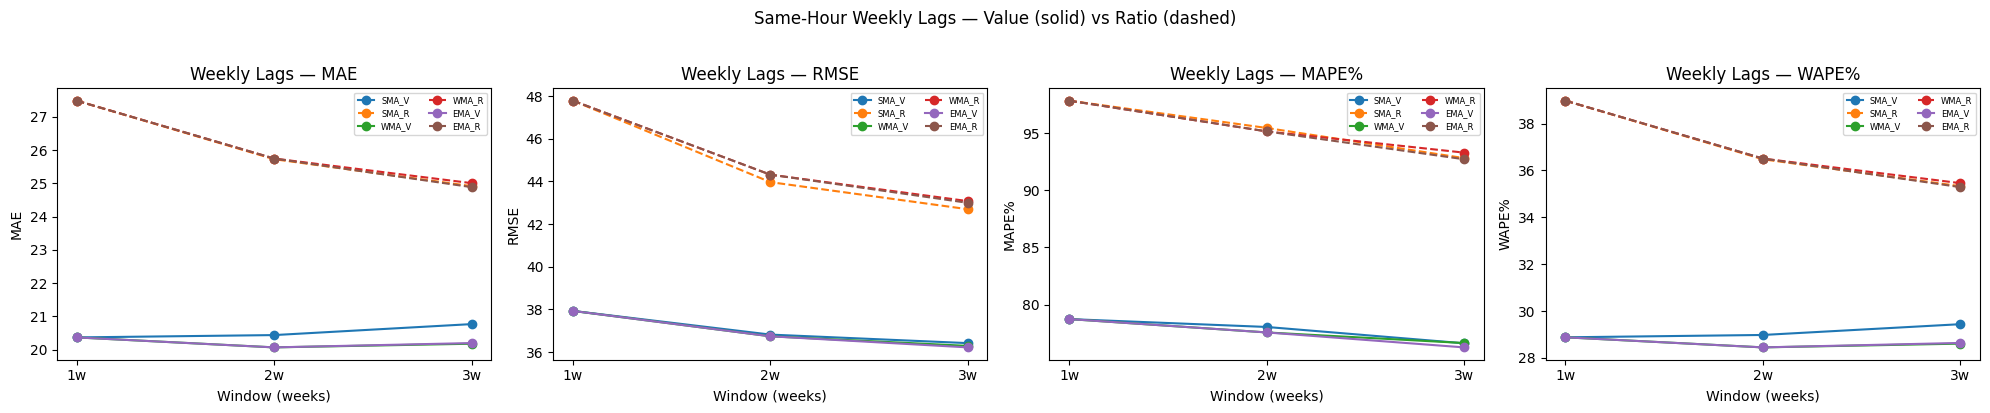


=== Best Model per Category (by MAE) ===

  naive  : Same Hour Last Week (t-168)     MAE=3.31  RMSE=12.54  MAPE=60.53%  WAPE=25.18%
  daily  : EMA_value w=6d                  MAE=24.12  RMSE=42.98  MAPE=104.31%  WAPE=34.20%
  weekly : WMA_value w=2w                  MAE=20.07  RMSE=36.74  MAPE=77.56%  WAPE=28.45%


In [38]:
# ── Visualise: Daily-lag MA results ─────────────────────────────────────────
import matplotlib.pyplot as plt

daily = ma_results_df[ma_results_df["lag_type"] == "daily"].copy()
weekly = ma_results_df[ma_results_df["lag_type"] == "weekly"].copy()

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
linestyles = {"value": "-", "ratio": "--"}

for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE%", "WAPE%"]):
    for model in ["SMA", "WMA", "EMA"]:
        for variant in ["value", "ratio"]:
            subset = daily[(daily["model"] == model) & (daily["variant"] == variant)]
            ax.plot(
                range(len(subset)), subset[metric].values,
                marker="o", linestyle=linestyles[variant],
                label=f"{model}_{variant[0].upper()}",
            )
    ax.set_xticks(range(len(DAILY_WINDOWS)))
    ax.set_xticklabels([f"{w}d" for w in DAILY_WINDOWS])
    ax.set_xlabel("Window (days)")
    ax.set_ylabel(metric)
    ax.set_title(f"Daily Lags — {metric}")
    ax.legend(fontsize=6, ncol=2)

fig.suptitle("Same-Hour Daily Lags — Value (solid) vs Ratio (dashed)", y=1.02)
plt.tight_layout()
plt.show()

# ── Visualise: Weekly-lag MA results ────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE%", "WAPE%"]):
    for model in ["SMA", "WMA", "EMA"]:
        for variant in ["value", "ratio"]:
            subset = weekly[(weekly["model"] == model) & (weekly["variant"] == variant)]
            ax.plot(
                range(len(subset)), subset[metric].values,
                marker="o", linestyle=linestyles[variant],
                label=f"{model}_{variant[0].upper()}",
            )
    ax.set_xticks(range(len(WEEKLY_WINDOWS)))
    ax.set_xticklabels([f"{w}w" for w in WEEKLY_WINDOWS])
    ax.set_xlabel("Window (weeks)")
    ax.set_ylabel(metric)
    ax.set_title(f"Weekly Lags — {metric}")
    ax.legend(fontsize=6, ncol=2)

fig.suptitle("Same-Hour Weekly Lags — Value (solid) vs Ratio (dashed)", y=1.02)
plt.tight_layout()
plt.show()

# ── Combined: best per category ─────────────────────────────────────────────
all_results = pd.concat([
    results_df.assign(lag_type="naive", model=results_df["model"], variant="-", window="-"),
    ma_results_df,
], ignore_index=True)

print("\n=== Best Model per Category (by MAE) ===\n")
for lag_type in ["naive", "daily", "weekly"]:
    sub = all_results[all_results["lag_type"] == lag_type]
    best = sub.loc[sub["MAE"].idxmin()]
    label = f"{best['model']}"
    if best["variant"] != "-":
        label += f"_{best['variant']}"
    if best["window"] != "-":
        label += f" w={best['window']}"
    print(f"  {lag_type:7s}: {label:30s}  MAE={best['MAE']:.2f}  RMSE={best['RMSE']:.2f}  MAPE={best['MAPE%']:.2f}%  WAPE={best['WAPE%']:.2f}%")

In [46]:
zone_data.hour.head()

166488   2022-01-09 00:00:00
166489   2022-01-09 01:00:00
166490   2022-01-09 02:00:00
166491   2022-01-09 03:00:00
166492   2022-01-09 04:00:00
Name: hour, dtype: datetime64[us]

In [47]:
zone_data.hour.tail()

167035   2022-01-31 19:00:00
167036   2022-01-31 20:00:00
167037   2022-01-31 21:00:00
167038   2022-01-31 22:00:00
167039   2022-01-31 23:00:00
Name: hour, dtype: datetime64[us]

In [18]:
target_col = "trip_count"
picked_feature = ['hour_of_day_sin', 'hour_of_day_cos', 'day_of_week_sin',
       'day_of_week_cos', 'month_sin', 'month_cos', 'pickup_longitude',
       'pickup_latitude', 'trip_count_lag_1', 'trip_count_lag_3',
       'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24']

## Using Tree Based Regression Models

### Train-Val-Test Split
Before we start predictions using the tree based regression models we take 1 months of 2022 pickup data and split it such that it can simulate daily retraining.

In daily retraining, model will be trained with data up to d-1.
Therefore, 
- we will use all data in January in each zone prior to 30 as training data
- We will then use data in January 30 in each zone as the validation data
- Finally, we will use data in January 31 in each zone as the test data

In [19]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from lightgbm import LGBMRegressor

# ── 1. Build feature matrix from January 2022 hourly demand ────────────────
# hourly_demand_panel already has: zone_coords (cell 31) + lag features (cell 32)
# Only need to add time features and cyclical encoding
df_feat = hourly_demand_panel[
    (hourly_demand_panel["hour"] >= "2022-01-01") &
    (hourly_demand_panel["hour"] < "2022-02-01")
].copy()

df_feat = add_time_features(df_feat)
df_feat = add_cyclical_features(df_feat)

# Drop rows with NaN in any picked feature (e.g. unknown zone IDs without coords)
df_feat = df_feat.dropna(subset=picked_feature)

print(f"Feature matrix: {df_feat.shape}")
print(f"Date range: {df_feat['hour'].min()} → {df_feat['hour'].max()}")
print(f"Features: {picked_feature}")

# ── 2. Train / Val / Test split (simulate daily retraining) ────────────────
train = df_feat[df_feat["hour"].dt.day < 30]
val   = df_feat[df_feat["hour"].dt.day == 30]
test  = df_feat[df_feat["hour"].dt.day == 31]

print(f"\nTrain: {len(train):,} rows  ({train['hour'].min()} → {train['hour'].max()})")
print(f"Val:   {len(val):,} rows  ({val['hour'].min()} → {val['hour'].max()})")
print(f"Test:  {len(test):,} rows  ({test['hour'].min()} → {test['hour'].max()})")

X_train, y_train = train[picked_feature], train[target_col]
X_val,   y_val   = val[picked_feature],   val[target_col]
X_test,  y_test  = test[picked_feature],  test[target_col]

# ── 3. Train models with default parameters ────────────────────────────────
models = {
    "RandomForest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "LightGBM": LGBMRegressor(random_state=42, verbosity=-1, n_jobs=-1),
}

results: list[dict] = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    # Evaluate on val and test
    for split_name, X_eval, y_eval in [("val", X_val, y_val), ("test", X_test, y_test)]:
        pred = model.predict(X_eval)
        actual = y_eval.values
        mask = actual > 0
        actual_mean = actual.mean()

        mae = np.abs(actual - pred).mean()
        rmse = np.sqrt(((actual - pred) ** 2).mean())
        mape = (np.abs(actual[mask] - pred[mask]) / actual[mask]).mean() * 100
        wape = (mae / actual_mean) * 100

        results.append({
            "model": name, "split": split_name,
            "MAE": mae, "RMSE": rmse, "MAPE%": mape, "WAPE%": wape,
        })
        print(f"  {split_name}: MAE={mae:.2f}  RMSE={rmse:.2f}  MAPE={mape:.2f}%  WAPE={wape:.2f}%")

tree_results_df = pd.DataFrame(results).round(2)
print("\n=== Tree-Based Regression Results (Default Params) ===\n")
print(tree_results_df.to_string(index=False))

Feature matrix: (184320, 19)
Date range: 2022-01-02 00:00:00 → 2022-01-31 23:00:00
Features: ['hour_of_day_sin', 'hour_of_day_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'pickup_longitude', 'pickup_latitude', 'trip_count_lag_1', 'trip_count_lag_3', 'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24']

Train: 172,032 rows  (2022-01-02 00:00:00 → 2022-01-29 23:00:00)
Val:   6,144 rows  (2022-01-30 00:00:00 → 2022-01-30 23:00:00)
Test:  6,144 rows  (2022-01-31 00:00:00 → 2022-01-31 23:00:00)

Training RandomForest...
  val: MAE=3.10  RMSE=10.43  MAPE=49.62%  WAPE=27.07%
  test: MAE=2.61  RMSE=8.43  MAPE=48.74%  WAPE=18.97%

Training GradientBoosting...
  val: MAE=3.70  RMSE=12.82  MAPE=59.21%  WAPE=32.28%
  test: MAE=3.12  RMSE=10.20  MAPE=60.67%  WAPE=22.65%

Training LightGBM...
  val: MAE=3.28  RMSE=10.79  MAPE=54.38%  WAPE=28.66%
  test: MAE=2.70  RMSE=8.34  MAPE=56.14%  WAPE=19.58%

=== Tree-Based Regression Results (Default Params) ===

           

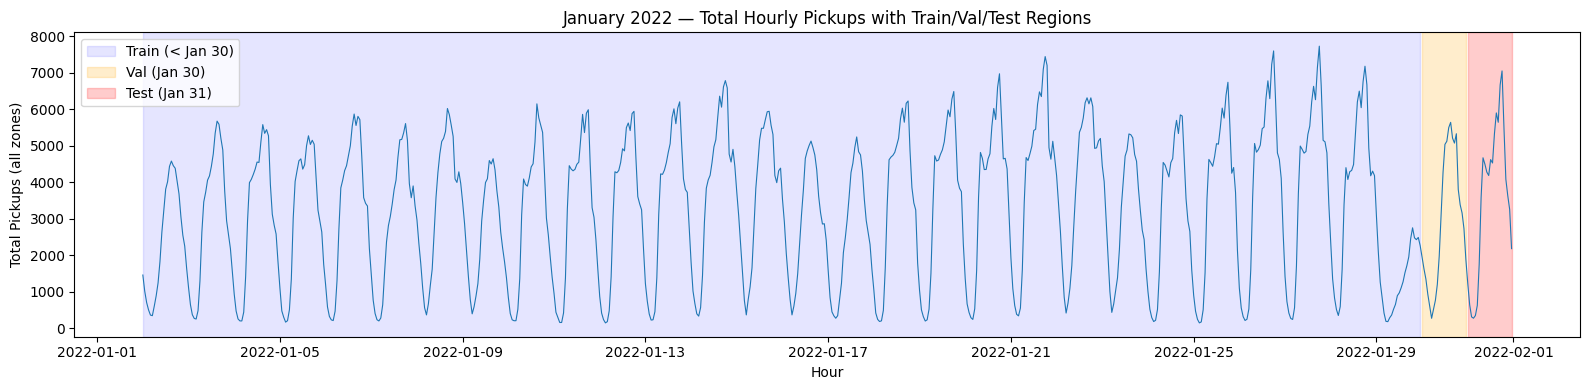

Val  date: 2022-01-30 (Sunday)
Test date: 2022-01-31 (Monday)

Val  total pickups:  70,349
Test total pickups:  84,687
Train avg daily pickups: 79,156


In [20]:
# ── Total pickups per hour across all zones (Jan 2022) ──────────────────────
hourly_total = df_feat.groupby("hour")[target_col].sum().reset_index()

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(hourly_total["hour"], hourly_total[target_col], linewidth=0.8)

# Shade train / val / test regions
ax.axvspan(train["hour"].min(), train["hour"].max(), alpha=0.1, color="blue", label="Train (< Jan 30)")
ax.axvspan(val["hour"].min(), val["hour"].max(), alpha=0.2, color="orange", label="Val (Jan 30)")
ax.axvspan(test["hour"].min(), test["hour"].max(), alpha=0.2, color="red", label="Test (Jan 31)")

ax.set_xlabel("Hour")
ax.set_ylabel("Total Pickups (all zones)")
ax.set_title("January 2022 — Total Hourly Pickups with Train/Val/Test Regions")
ax.legend()
plt.tight_layout()
plt.show()

# Print day-of-week for val and test
import calendar
val_date = val["hour"].dt.date.iloc[0]
test_date = test["hour"].dt.date.iloc[0]
print(f"Val  date: {val_date} ({calendar.day_name[val_date.weekday()]})")
print(f"Test date: {test_date} ({calendar.day_name[test_date.weekday()]})")
print(f"\nVal  total pickups:  {val[target_col].sum():,}")
print(f"Test total pickups:  {test[target_col].sum():,}")
print(f"Train avg daily pickups: {train.groupby(train['hour'].dt.date)[target_col].sum().mean():,.0f}")

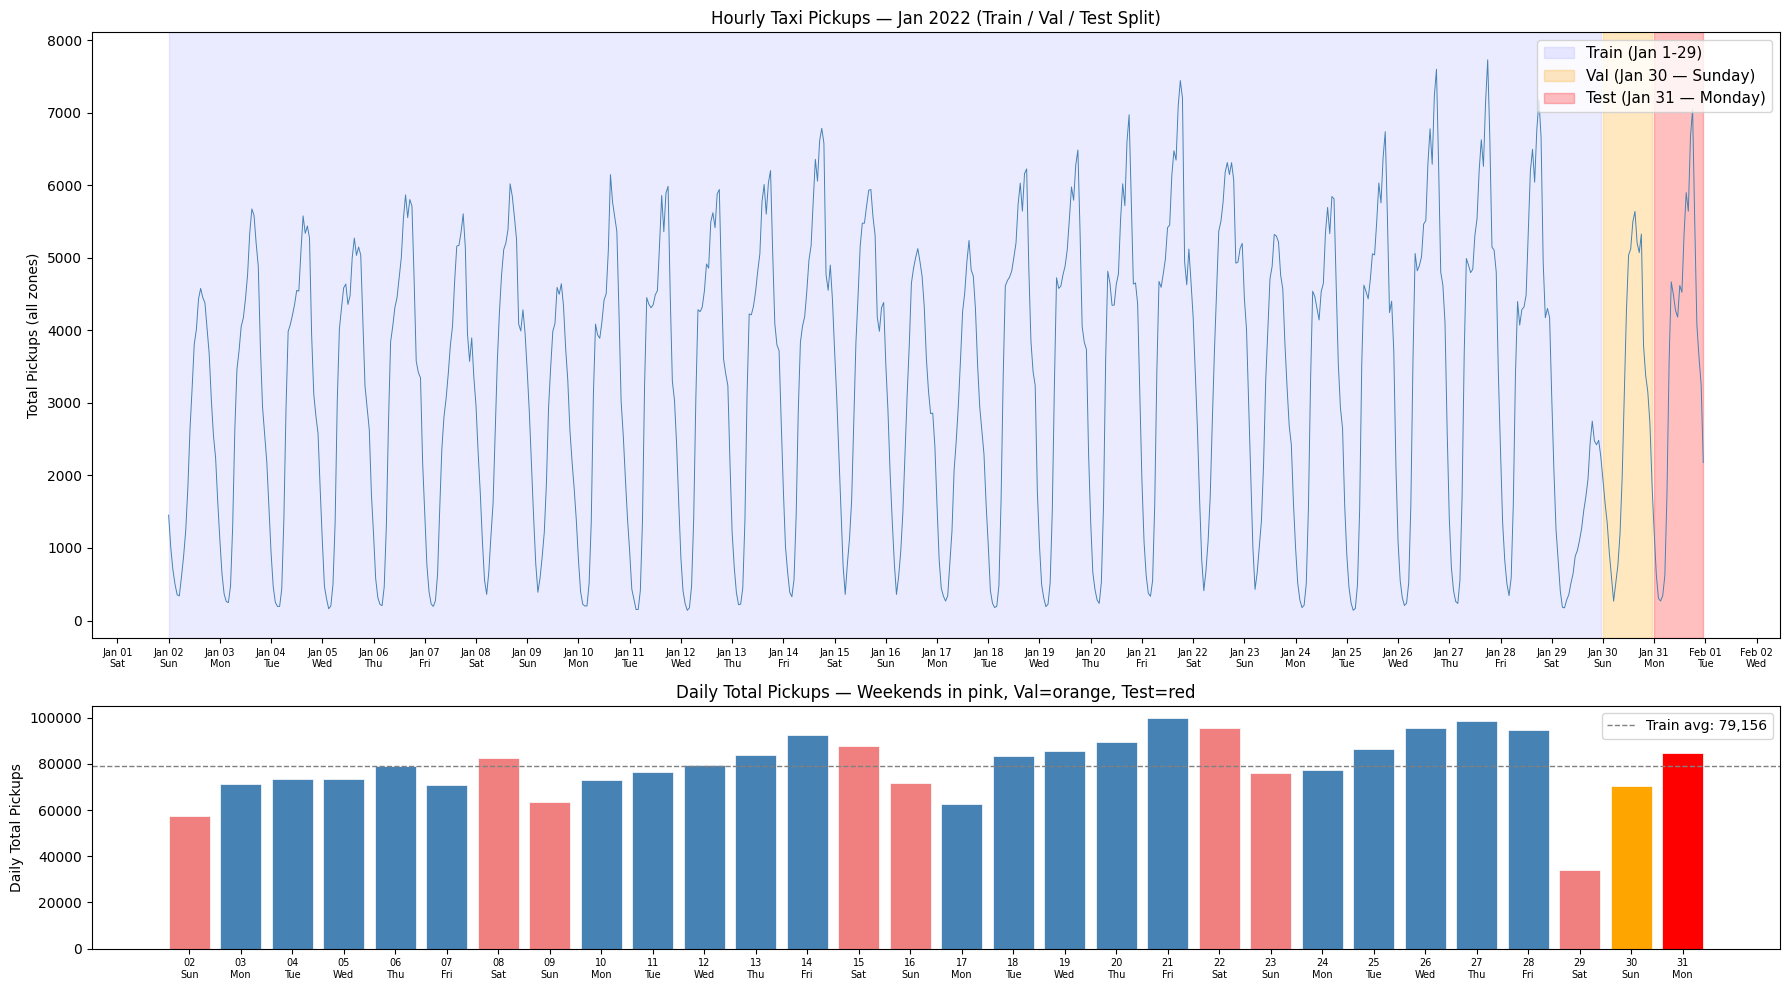


Val  date: 2022-01-30 (Sunday)
Test date: 2022-01-31 (Monday)

Val  total pickups:  70,349
Test total pickups:  84,687
Train avg daily pickups: 79,156

Train weekday avg: 82,399
Train weekend avg: 71,048
Weekend/Weekday ratio: 86.22%


In [21]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import calendar

target_col = "trip_count"

# Aggregate total pickups per hour across all zones
hourly_total = df_feat.groupby("hour")[target_col].sum().reset_index()
hourly_total["day_name"] = hourly_total["hour"].dt.day_name()
hourly_total["date"] = hourly_total["hour"].dt.date

# Identify train/val/test boundaries
train = df_feat[df_feat["hour"].dt.day < 30]
val   = df_feat[df_feat["hour"].dt.day == 30]
test  = df_feat[df_feat["hour"].dt.day == 31]

val_date  = val["hour"].dt.date.iloc[0]
test_date = test["hour"].dt.date.iloc[0]

# ── Figure: 2 subplots ──────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), gridspec_kw={"height_ratios": [3, 1.2]})

# ── Top: Full timeline with train/val/test shading ──────────────────────────
ax1.plot(hourly_total["hour"], hourly_total[target_col], linewidth=0.7, color="steelblue")

ax1.axvspan(train["hour"].min(), train["hour"].max(), alpha=0.08, color="blue", label="Train (Jan 1-29)")
ax1.axvspan(val["hour"].min(), val["hour"].max(), alpha=0.25, color="orange", label=f"Val (Jan 30 — {calendar.day_name[val_date.weekday()]})")
ax1.axvspan(test["hour"].min(), test["hour"].max(), alpha=0.25, color="red", label=f"Test (Jan 31 — {calendar.day_name[test_date.weekday()]})")

ax1.set_ylabel("Total Pickups (all zones)")
ax1.set_title("Hourly Taxi Pickups — Jan 2022 (Train / Val / Test Split)")
ax1.legend(loc="upper right", fontsize=11)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%a"))
ax1.xaxis.set_major_locator(mdates.DayLocator())
ax1.tick_params(axis="x", rotation=0, labelsize=7)

# ── Bottom: Daily total pickups as bar chart ────────────────────────────────
daily_total = df_feat.groupby(df_feat["hour"].dt.date)[target_col].sum().reset_index()
daily_total.columns = ["date", "total_pickups"]
daily_total["day_name"] = pd.to_datetime(daily_total["date"]).dt.day_name()
daily_total["is_weekend"] = pd.to_datetime(daily_total["date"]).dt.dayofweek >= 5

colors = []
for _, row in daily_total.iterrows():
    if row["date"] == val_date:
        colors.append("orange")
    elif row["date"] == test_date:
        colors.append("red")
    elif row["is_weekend"]:
        colors.append("lightcoral")
    else:
        colors.append("steelblue")

ax2.bar(range(len(daily_total)), daily_total["total_pickups"], color=colors, edgecolor="white", linewidth=0.5)
ax2.set_xticks(range(len(daily_total)))
ax2.set_xticklabels([f"{d.strftime('%d')}\n{dn[:3]}" for d, dn in zip(daily_total["date"], daily_total["day_name"])], fontsize=7)
ax2.set_ylabel("Daily Total Pickups")
ax2.set_title("Daily Total Pickups — Weekends in pink, Val=orange, Test=red")

# Add horizontal line for average
avg_train = daily_total[daily_total["date"] < val_date]["total_pickups"].mean()
ax2.axhline(avg_train, color="gray", linestyle="--", linewidth=1, label=f"Train avg: {avg_train:,.0f}")
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

# ── Stats ────────────────────────────────────────────────────────────────────
print(f"\nVal  date: {val_date} ({calendar.day_name[val_date.weekday()]})")
print(f"Test date: {test_date} ({calendar.day_name[test_date.weekday()]})")
print(f"\nVal  total pickups:  {val[target_col].sum():,}")
print(f"Test total pickups:  {test[target_col].sum():,}")
print(f"Train avg daily pickups: {train.groupby(train['hour'].dt.date)[target_col].sum().mean():,.0f}")

# Weekend vs weekday stats in train
train_daily = train.groupby(train["hour"].dt.date)[target_col].sum().reset_index()
train_daily.columns = ["date", "total"]
train_daily["is_weekend"] = pd.to_datetime(train_daily["date"]).dt.dayofweek >= 5
print(f"\nTrain weekday avg: {train_daily[~train_daily['is_weekend']]['total'].mean():,.0f}")
print(f"Train weekend avg: {train_daily[train_daily['is_weekend']]['total'].mean():,.0f}")
print(f"Weekend/Weekday ratio: {train_daily[train_daily['is_weekend']]['total'].mean() / train_daily[~train_daily['is_weekend']]['total'].mean():.2%}")


In [22]:

# Check what variables are available in the kernel
print(type(df_feat))
print(df_feat.shape)
print(df_feat.columns.tolist())


<class 'pandas.DataFrame'>
(184320, 19)
['pulocationid', 'hour', 'trip_count', 'hour_of_day', 'day_of_week', 'month', 'hour_of_day_sin', 'hour_of_day_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'pickup_longitude', 'pickup_latitude', 'trip_count_lag_1', 'trip_count_lag_3', 'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24']


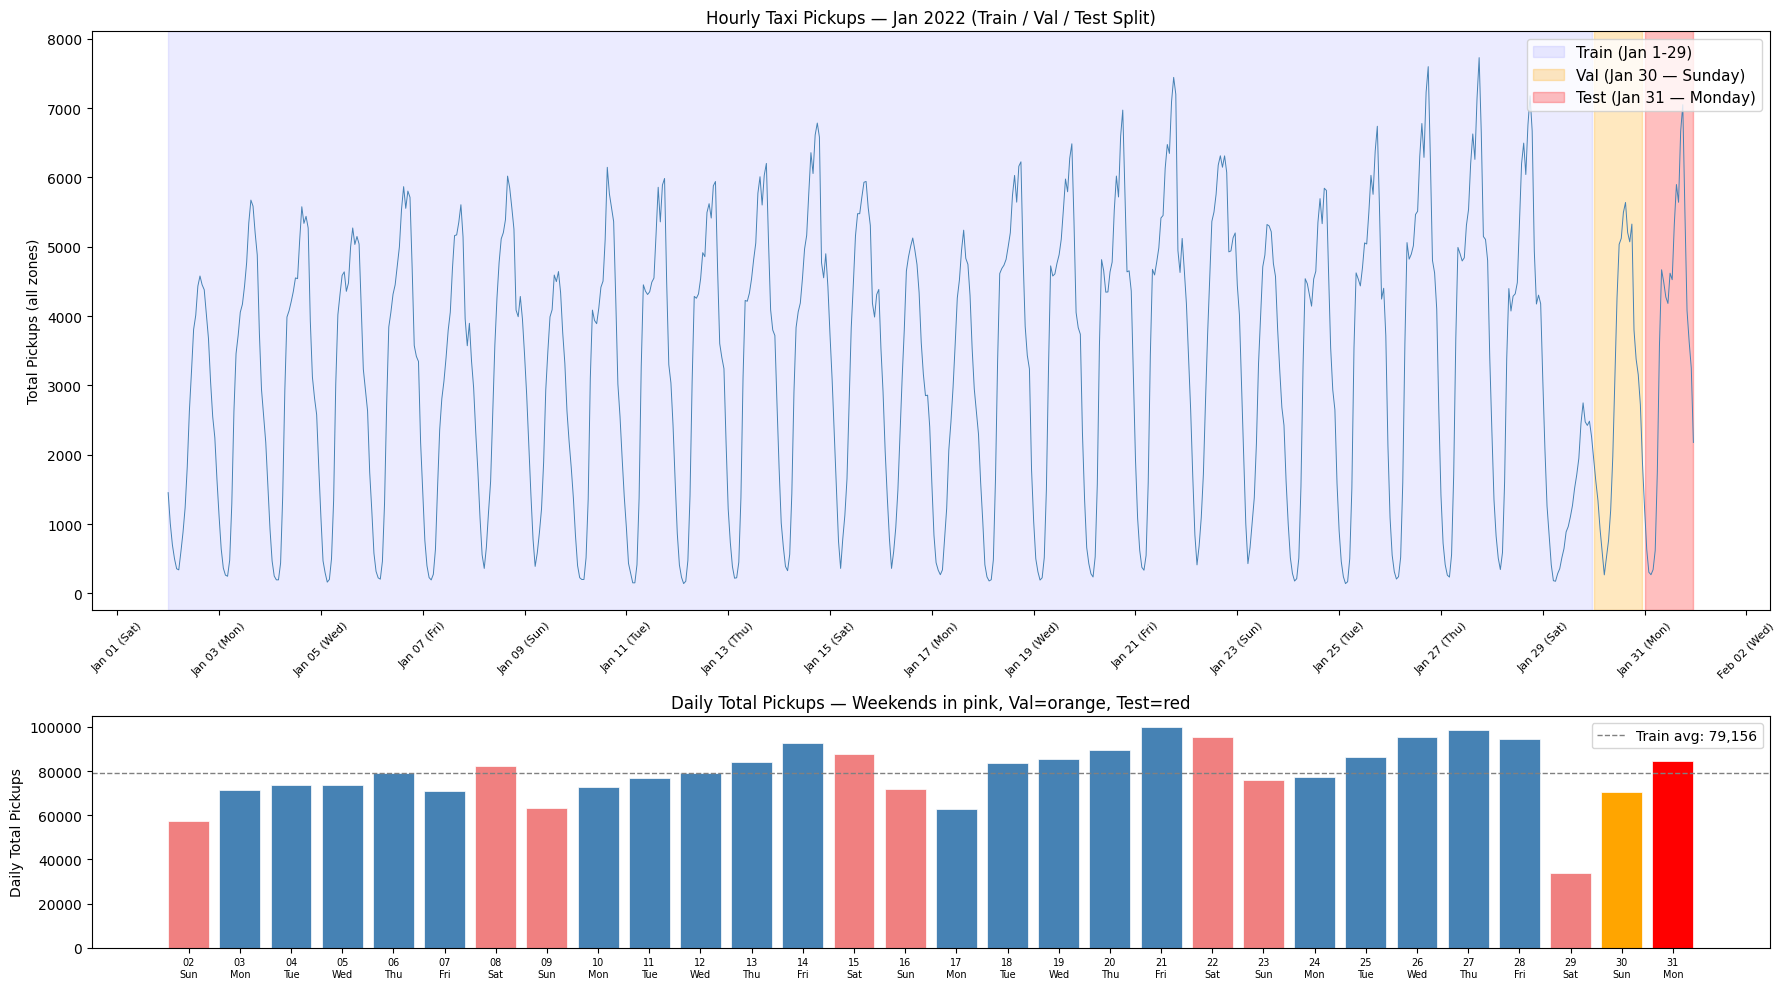


Val  date: 2022-01-30 (Sunday)
Test date: 2022-01-31 (Monday)

Val  total pickups:  70,349
Test total pickups:  84,687

Train weekday avg: 82,399
Train weekend avg: 71,048
Weekend/Weekday ratio: 86.22%


In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import calendar

target_col = "trip_count"

# Splits
train = df_feat[df_feat["hour"].dt.day < 30]
val   = df_feat[df_feat["hour"].dt.day == 30]
test  = df_feat[df_feat["hour"].dt.day == 31]

val_date  = val["hour"].dt.date.iloc[0]
test_date = test["hour"].dt.date.iloc[0]

# Hourly totals
hourly_total = df_feat.groupby("hour")[target_col].sum().reset_index()

# Daily totals
daily_total = df_feat.groupby(df_feat["hour"].dt.date)[target_col].sum().reset_index()
daily_total.columns = ["date", "total_pickups"]
daily_total["day_name"] = pd.to_datetime(daily_total["date"]).dt.day_name()
daily_total["is_weekend"] = pd.to_datetime(daily_total["date"]).dt.dayofweek >= 5

# ── Figure ───────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), gridspec_kw={"height_ratios": [3, 1.2]})

# Top: hourly timeline
ax1.plot(hourly_total["hour"], hourly_total[target_col], linewidth=0.7, color="steelblue")
ax1.axvspan(train["hour"].min(), train["hour"].max(), alpha=0.08, color="blue", label="Train (Jan 1-29)")
ax1.axvspan(val["hour"].min(), val["hour"].max(), alpha=0.25, color="orange",
            label=f"Val (Jan 30 — {calendar.day_name[val_date.weekday()]})")
ax1.axvspan(test["hour"].min(), test["hour"].max(), alpha=0.25, color="red",
            label=f"Test (Jan 31 — {calendar.day_name[test_date.weekday()]})")
ax1.set_ylabel("Total Pickups (all zones)")
ax1.set_title("Hourly Taxi Pickups — Jan 2022 (Train / Val / Test Split)")
ax1.legend(loc="upper right", fontsize=11)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d (%a)"))
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax1.tick_params(axis="x", rotation=45, labelsize=8)

# Bottom: daily bar chart
colors = []
for _, row in daily_total.iterrows():
    if row["date"] == val_date:
        colors.append("orange")
    elif row["date"] == test_date:
        colors.append("red")
    elif row["is_weekend"]:
        colors.append("lightcoral")
    else:
        colors.append("steelblue")

ax2.bar(range(len(daily_total)), daily_total["total_pickups"], color=colors, edgecolor="white", linewidth=0.5)
ax2.set_xticks(range(len(daily_total)))
ax2.set_xticklabels([f"{d.strftime('%d')}\n{dn[:3]}" for d, dn in zip(daily_total["date"], daily_total["day_name"])], fontsize=7)
ax2.set_ylabel("Daily Total Pickups")
ax2.set_title("Daily Total Pickups — Weekends in pink, Val=orange, Test=red")

avg_train = daily_total[daily_total["date"] < val_date]["total_pickups"].mean()
ax2.axhline(avg_train, color="gray", linestyle="--", linewidth=1, label=f"Train avg: {avg_train:,.0f}")
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

# Stats
print(f"\nVal  date: {val_date} ({calendar.day_name[val_date.weekday()]})")
print(f"Test date: {test_date} ({calendar.day_name[test_date.weekday()]})")
print(f"\nVal  total pickups:  {val[target_col].sum():,}")
print(f"Test total pickups:  {test[target_col].sum():,}")

train_daily = train.groupby(train["hour"].dt.date)[target_col].sum().reset_index()
train_daily.columns = ["date", "total"]
train_daily["is_weekend"] = pd.to_datetime(train_daily["date"]).dt.dayofweek >= 5
print(f"\nTrain weekday avg: {train_daily[~train_daily['is_weekend']]['total'].mean():,.0f}")
print(f"Train weekend avg: {train_daily[train_daily['is_weekend']]['total'].mean():,.0f}")
print(f"Weekend/Weekday ratio: {train_daily[train_daily['is_weekend']]['total'].mean() / train_daily[~train_daily['is_weekend']]['total'].mean():.2%}")


In [24]:

# Check current lag features
print("Current lag hours:", LAG_HOURS)
print("Current features:", picked_feature)


Current lag hours: [1, 3, 6, 12, 24]
Current features: ['hour_of_day_sin', 'hour_of_day_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'pickup_longitude', 'pickup_latitude', 'trip_count_lag_1', 'trip_count_lag_3', 'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24']


In [25]:

# Add 168-hour (1-week) lag to hourly_demand_panel
NEW_LAG = 168

hourly_demand_panel = hourly_demand_panel.sort_values(["pulocationid", "hour"])
hourly_demand_panel[f"trip_count_lag_{NEW_LAG}"] = (
    hourly_demand_panel.groupby("pulocationid")["trip_count"].shift(NEW_LAG)
)

print(f"Added trip_count_lag_{NEW_LAG}")
print(f"Non-null count: {hourly_demand_panel[f'trip_count_lag_{NEW_LAG}'].notna().sum():,}")
print(f"Null count: {hourly_demand_panel[f'trip_count_lag_{NEW_LAG}'].isna().sum():,}")


Added trip_count_lag_168
Non-null count: 511,680
Null count: 43,680


In [26]:

# Rebuild feature matrix with the new lag and retrain
LAG_HOURS_NEW = [1, 3, 6, 12, 24, 168]

picked_feature_new = picked_feature + [f"trip_count_lag_{NEW_LAG}"]

df_feat_new = hourly_demand_panel[
    (hourly_demand_panel["hour"] >= "2022-01-01") &
    (hourly_demand_panel["hour"] < "2022-02-01")
].copy()

df_feat_new = add_time_features(df_feat_new)
df_feat_new = add_cyclical_features(df_feat_new)
df_feat_new = df_feat_new.dropna(subset=picked_feature_new)

print(f"Feature matrix: {df_feat_new.shape}")
print(f"Date range: {df_feat_new['hour'].min()} → {df_feat_new['hour'].max()}")
print(f"Features: {picked_feature_new}")

# Split
train_new = df_feat_new[df_feat_new["hour"].dt.day < 30]
val_new   = df_feat_new[df_feat_new["hour"].dt.day == 30]
test_new  = df_feat_new[df_feat_new["hour"].dt.day == 31]

print(f"\nTrain: {len(train_new):,} rows")
print(f"Val:   {len(val_new):,} rows")
print(f"Test:  {len(test_new):,} rows")

X_train_new, y_train_new = train_new[picked_feature_new], train_new[target_col]
X_val_new,   y_val_new   = val_new[picked_feature_new],   val_new[target_col]
X_test_new,  y_test_new  = test_new[picked_feature_new],  test_new[target_col]


Feature matrix: (141312, 20)
Date range: 2022-01-09 00:00:00 → 2022-01-31 23:00:00
Features: ['hour_of_day_sin', 'hour_of_day_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'pickup_longitude', 'pickup_latitude', 'trip_count_lag_1', 'trip_count_lag_3', 'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24', 'trip_count_lag_168']

Train: 129,024 rows
Val:   6,144 rows
Test:  6,144 rows


In [27]:

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

models = {
    "LGBMRegressor": LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=42, verbosity=-1),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GBRegressor": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=42),
}

def mape(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100

# ── Train & evaluate: OLD features (no lag_168) ─────────────────────────────
# Use same rows as new (Jan 9+) for fair comparison
df_feat_old = df_feat_new.copy()
X_train_old = train_new[picked_feature]
X_val_old   = val_new[picked_feature]
X_test_old  = test_new[picked_feature]

results = []
for name, model in models.items():
    # OLD (without lag_168)
    model_old = model.__class__(**model.get_params())
    model_old.fit(X_train_old, y_train_new)
    for split_name, X_ev, y_ev in [("val", X_val_old, y_val_new), ("test", X_test_old, y_test_new)]:
        pred = model_old.predict(X_ev)
        results.append({
            "model": name, "features": "without lag_168", "split": split_name,
            "MAE": mean_absolute_error(y_ev, pred),
            "RMSE": np.sqrt(mean_squared_error(y_ev, pred)),
            "MAPE%": mape(y_ev.values, pred),
            "WAPE%": wape(y_ev.values, pred),
        })

    # NEW (with lag_168)
    model_new = model.__class__(**model.get_params())
    model_new.fit(X_train_new, y_train_new)
    for split_name, X_ev, y_ev in [("val", X_val_new, y_val_new), ("test", X_test_new, y_test_new)]:
        pred = model_new.predict(X_ev)
        results.append({
            "model": name, "features": "with lag_168", "split": split_name,
            "MAE": mean_absolute_error(y_ev, pred),
            "RMSE": np.sqrt(mean_squared_error(y_ev, pred)),
            "MAPE%": mape(y_ev.values, pred),
            "WAPE%": wape(y_ev.values, pred),
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


        model        features split      MAE      RMSE     MAPE%     WAPE%
LGBMRegressor without lag_168   val 3.380875 11.235348 54.478153 29.527210
LGBMRegressor without lag_168  test 2.606307  7.988248 54.099368 18.908627
LGBMRegressor    with lag_168   val 2.593602  8.453798 51.120191 22.651486
LGBMRegressor    with lag_168  test 2.320327  7.107247 48.209339 16.833859
 RandomForest without lag_168   val 3.311302 11.173627 49.923116 28.919583
 RandomForest without lag_168  test 2.684119  8.706905 48.864934 19.473154
 RandomForest    with lag_168   val 2.541425  8.105096 49.356915 22.195784
 RandomForest    with lag_168  test 2.373592  7.290489 46.012991 17.220290
  GBRegressor without lag_168   val 3.725427 12.793644 59.527895 32.536392
  GBRegressor without lag_168  test 3.179130 10.141225 61.446549 23.064429
  GBRegressor    with lag_168   val 2.656337  8.400870 52.844296 23.199384
  GBRegressor    with lag_168  test 2.473137  7.415175 49.621337 17.942488


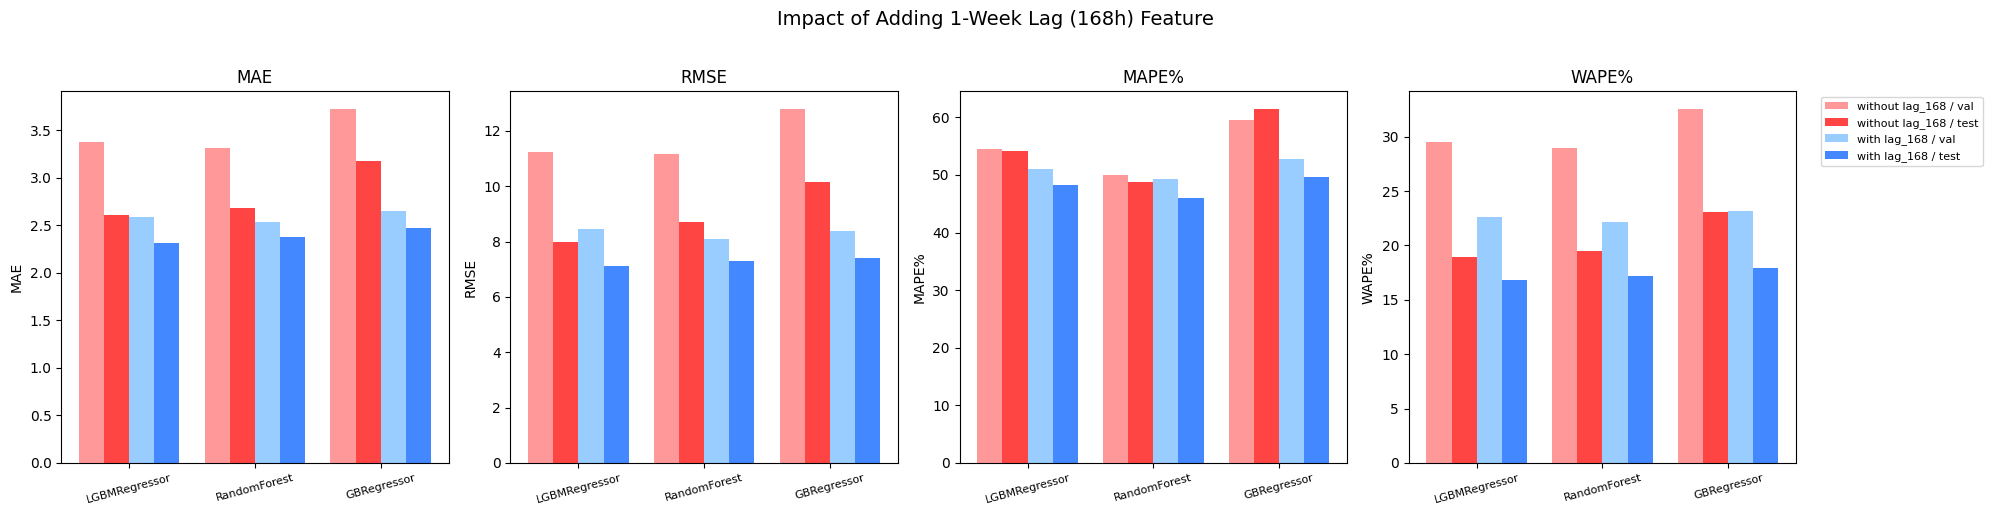


── Improvement from adding lag_168 ──
  LGBMRegressor  val: MAE ↓23.3%  WAPE ↓23.3%
  LGBMRegressor test: MAE ↓11.0%  WAPE ↓11.0%
   RandomForest  val: MAE ↓23.2%  WAPE ↓23.2%
   RandomForest test: MAE ↓11.6%  WAPE ↓11.6%
    GBRegressor  val: MAE ↓28.7%  WAPE ↓28.7%
    GBRegressor test: MAE ↓22.2%  WAPE ↓22.2%


In [28]:

# Visualize improvement
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
metrics = ["MAE", "RMSE", "MAPE%", "WAPE%"]
model_names = results_df["model"].unique()

for ax, metric in zip(axes, metrics):
    x = np.arange(len(model_names))
    width = 0.2

    for i, (feat, split) in enumerate([
        ("without lag_168", "val"), ("without lag_168", "test"),
        ("with lag_168", "val"), ("with lag_168", "test"),
    ]):
        subset = results_df[(results_df["features"] == feat) & (results_df["split"] == split)]
        color = ["#ff9999", "#ff4444", "#99ccff", "#4488ff"][i]
        label = f"{feat} / {split}"
        ax.bar(x + i * width, subset[metric].values, width, label=label, color=color)

    ax.set_xticks(x + 1.5 * width)
    ax.set_xticklabels(model_names, fontsize=8, rotation=15)
    ax.set_title(metric)
    ax.set_ylabel(metric)

axes[-1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
fig.suptitle("Impact of Adding 1-Week Lag (168h) Feature", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Print improvement summary
print("\n── Improvement from adding lag_168 ──")
for name in model_names:
    for split in ["val", "test"]:
        old = results_df[(results_df["model"] == name) & (results_df["features"] == "without lag_168") & (results_df["split"] == split)]
        new = results_df[(results_df["model"] == name) & (results_df["features"] == "with lag_168") & (results_df["split"] == split)]
        mae_drop = (old["MAE"].values[0] - new["MAE"].values[0]) / old["MAE"].values[0] * 100
        wape_drop = (old["WAPE%"].values[0] - new["WAPE%"].values[0]) / old["WAPE%"].values[0] * 100
        print(f"{name:>15} {split:>4}: MAE ↓{mae_drop:.1f}%  WAPE ↓{wape_drop:.1f}%")


In [29]:

# Find top 3 zones by total trip_count
zone_totals = df_feat_new.groupby("pulocationid")[target_col].sum().sort_values(ascending=False)
top3_zones = zone_totals.head(3).index.tolist()
print("Top 3 zones by total pickups:")
for z in top3_zones:
    print(f"  Zone {z}: {zone_totals[z]:,.0f} total pickups")


Top 3 zones by total pickups:
  Zone 237: 95,384 total pickups
  Zone 236: 94,482 total pickups
  Zone 132: 70,592 total pickups


In [30]:

# Get predictions from all 3 models (with lag_168) for every row
models_trained = {}
for name, model in models.items():
    m = model.__class__(**model.get_params())
    m.fit(X_train_new, y_train_new)
    models_trained[name] = m

# Build prediction df for full val+test period
eval_df = pd.concat([val_new, test_new]).copy()
eval_X = eval_df[picked_feature_new]

for name, m in models_trained.items():
    eval_df[f"pred_{name}"] = m.predict(eval_X)

# Also get predictions on train (last 3 days of train for context)
train_tail = train_new[train_new["hour"] >= "2022-01-27"].copy()
train_X = train_tail[picked_feature_new]
for name, m in models_trained.items():
    train_tail[f"pred_{name}"] = m.predict(train_X)

full_plot = pd.concat([train_tail, eval_df]).sort_values(["pulocationid", "hour"])
print(f"Plot data: {len(full_plot):,} rows, {full_plot['hour'].min()} → {full_plot['hour'].max()}")


Plot data: 30,720 rows, 2022-01-27 00:00:00 → 2022-01-31 23:00:00


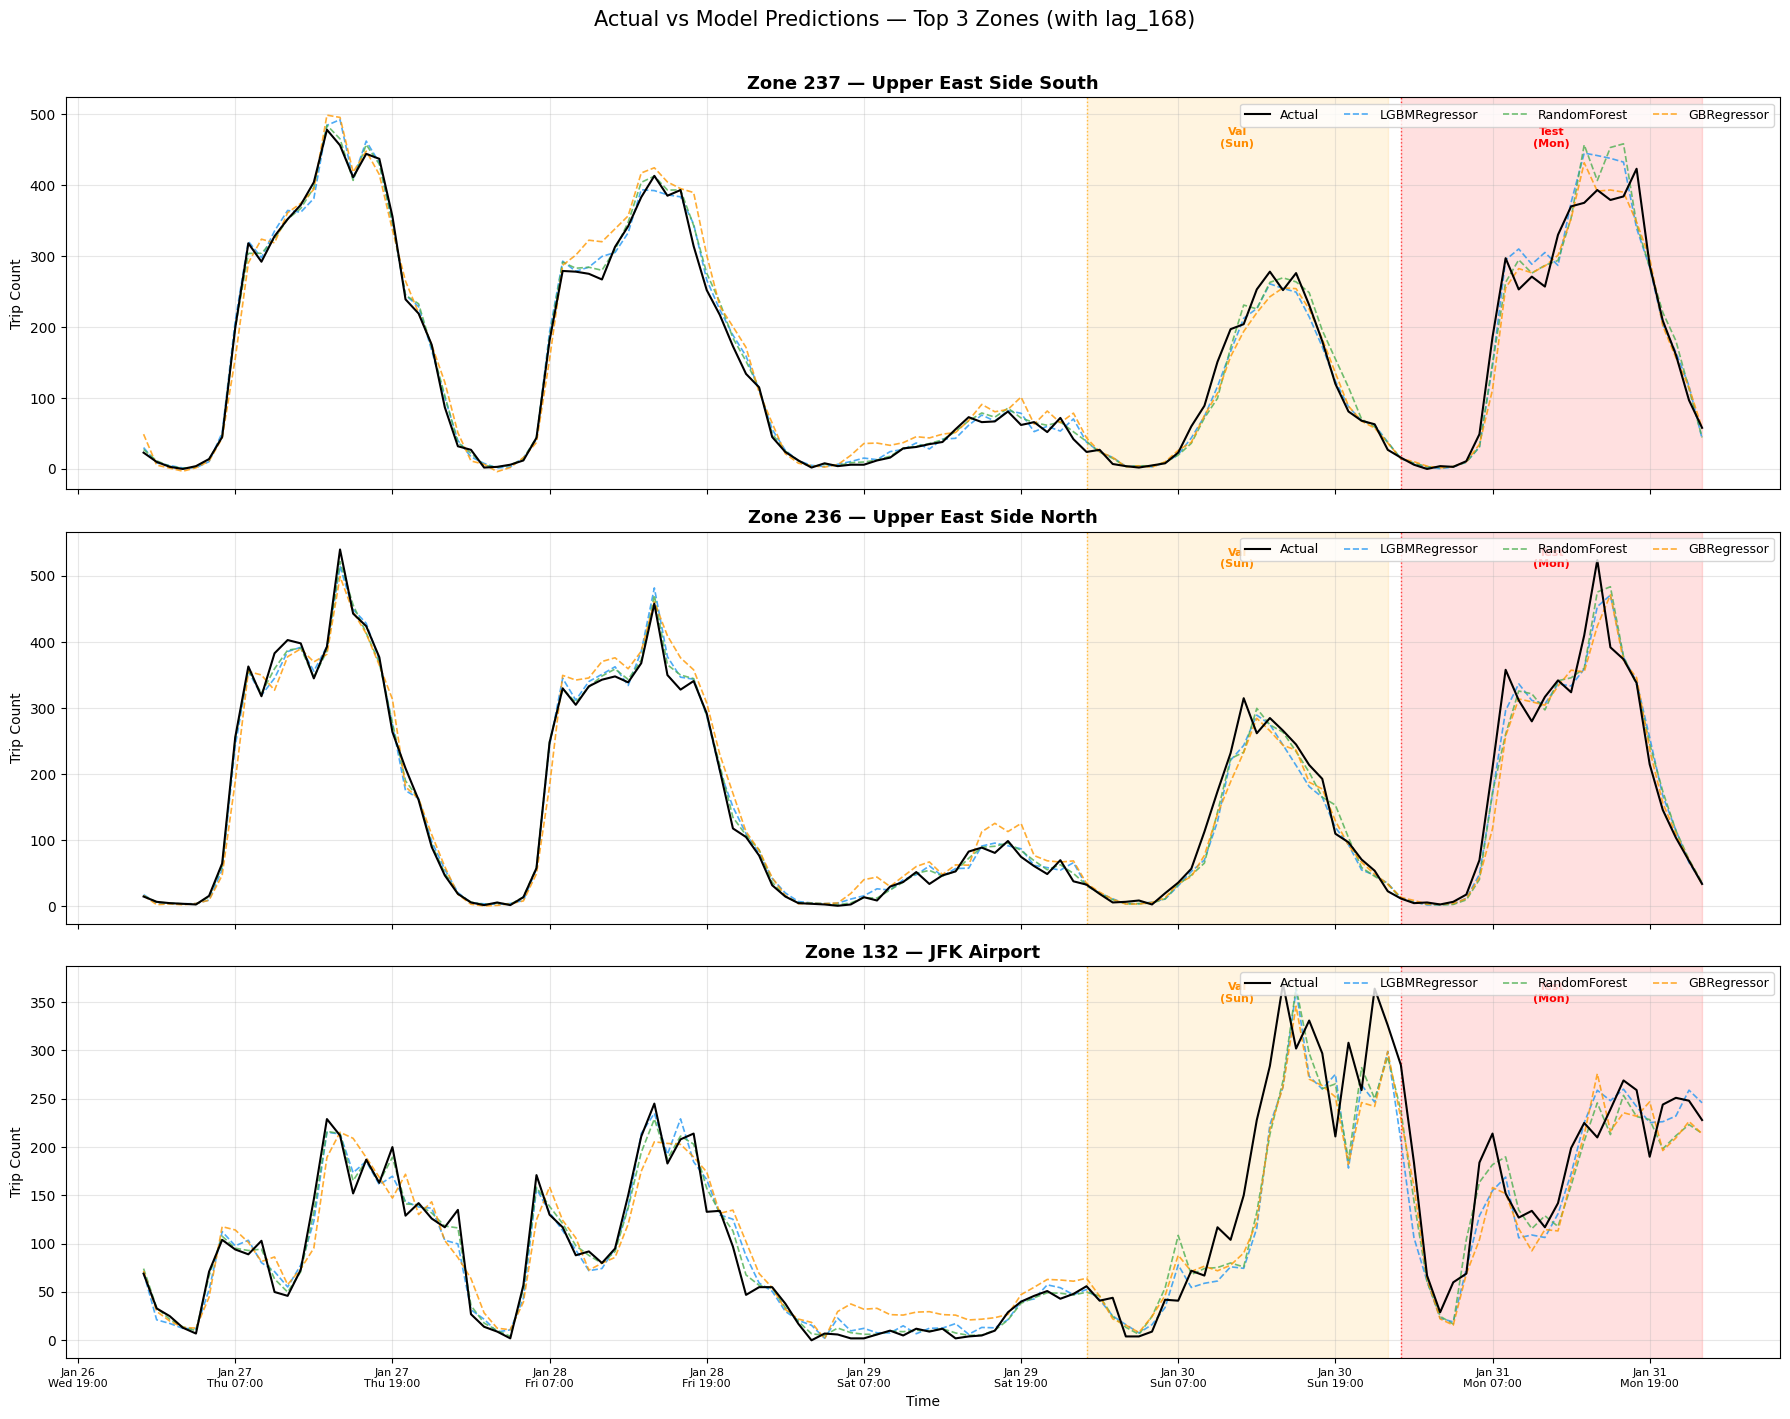

In [31]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

zone_names = {237: "Upper East Side South", 236: "Upper East Side North", 132: "JFK Airport"}

fig, axes = plt.subplots(3, 1, figsize=(18, 14), sharex=True)

model_colors = {
    "LGBMRegressor": "#2196F3",
    "RandomForest": "#4CAF50",
    "GBRegressor": "#FF9800",
}

for ax, zone in zip(axes, top3_zones):
    zdata = full_plot[full_plot["pulocationid"] == zone].sort_values("hour")

    # Actual
    ax.plot(zdata["hour"], zdata[target_col], color="black", linewidth=1.5, label="Actual", zorder=5)

    # Model predictions
    for name, color in model_colors.items():
        ax.plot(zdata["hour"], zdata[f"pred_{name}"], color=color, linewidth=1.2,
                alpha=0.8, linestyle="--", label=name)

    # Shade val/test
    ax.axvspan(val_new["hour"].min(), val_new["hour"].max(), alpha=0.12, color="orange")
    ax.axvspan(test_new["hour"].min(), test_new["hour"].max(), alpha=0.12, color="red")

    # Vertical lines at split boundaries
    ax.axvline(val_new["hour"].min(), color="orange", linestyle=":", linewidth=1, alpha=0.7)
    ax.axvline(test_new["hour"].min(), color="red", linestyle=":", linewidth=1, alpha=0.7)

    label = zone_names.get(zone, f"Zone {zone}")
    ax.set_ylabel("Trip Count")
    ax.set_title(f"Zone {zone} — {label}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, ncol=4)
    ax.grid(True, alpha=0.3)

    # Annotate regions
    mid_val = val_new["hour"].min() + (val_new["hour"].max() - val_new["hour"].min()) / 2
    mid_test = test_new["hour"].min() + (test_new["hour"].max() - test_new["hour"].min()) / 2
    ymax = zdata[target_col].max()
    ax.text(mid_val, ymax * 0.95, "Val\n(Sun)", ha="center", fontsize=8, color="darkorange", fontweight="bold")
    ax.text(mid_test, ymax * 0.95, "Test\n(Mon)", ha="center", fontsize=8, color="red", fontweight="bold")

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%a %H:%M"))
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=12))
axes[-1].tick_params(axis="x", rotation=0, labelsize=8)
axes[-1].set_xlabel("Time")

fig.suptitle("Actual vs Model Predictions — Top 3 Zones (with lag_168)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()


In [3]:
"A".lower()

'a'

In [32]:

# Per-zone per-model metrics on val and test
rows = []
for zone in top3_zones:
    zdata_val = eval_df[eval_df["pulocationid"] == zone]
    for name in models_trained:
        for split_name, sdata in [("val", zdata_val[zdata_val["hour"].dt.day == 30]),
                                   ("test", zdata_val[zdata_val["hour"].dt.day == 31])]:
            y_true = sdata[target_col].values
            y_pred = sdata[f"pred_{name}"].values
            rows.append({
                "zone": zone, "model": name, "split": split_name,
                "MAE": mean_absolute_error(y_true, y_pred),
                "WAPE%": wape(y_true, y_pred),
            })

zone_metrics = pd.DataFrame(rows)
label_map = {237: "237 (UES South)", 236: "236 (UES North)", 132: "132 (JFK)"}
zone_metrics["zone_label"] = zone_metrics["zone"].map(label_map)
print(zone_metrics[["zone_label", "model", "split", "MAE", "WAPE%"]].to_string(index=False))


     zone_label         model split       MAE     WAPE%
237 (UES South) LGBMRegressor   val 10.852380  9.903312
237 (UES South) LGBMRegressor  test 24.968925 12.435240
237 (UES South)  RandomForest   val 15.445625 14.094867
237 (UES South)  RandomForest  test 25.573333 12.736252
237 (UES South)   GBRegressor   val 13.070203 11.927182
237 (UES South)   GBRegressor  test 18.637066  9.281793
236 (UES North) LGBMRegressor   val 16.991080 14.338464
236 (UES North) LGBMRegressor  test 20.914599 10.306989
236 (UES North)  RandomForest   val 16.119792 13.603200
236 (UES North)  RandomForest  test 22.897292 11.284086
236 (UES North)   GBRegressor   val 16.435284 13.869438
236 (UES North)   GBRegressor  test 25.289097 12.462799
      132 (JFK) LGBMRegressor   val 43.958288 26.178633
      132 (JFK) LGBMRegressor  test 26.002726 14.425923
      132 (JFK)  RandomForest   val 43.115000 25.676427
      132 (JFK)  RandomForest  test 27.226250 15.104716
      132 (JFK)   GBRegressor   val 41.807415 24